# Домашнее задание 2. Полносвязные нейронные сети

Реализуйте полносвязную нейронную сеть на NumPy и исследуйте её обучение
на задаче двумерной классификации. Работа состоит из двух частей:
реализации и проверки компонентов, затем сравнения моделей и режимов обучения.


**Фамилия и имя:** Явакаев Роман  
**Группа:** Б05-404


## Предварительные сведения

Предполагается знание матричного дифференцирования, обратного распространения
ошибки, softmax, кросс-энтропии и стохастического градиентного спуска,
а также опыт работы с массивами NumPy.

Слои, аналитические градиенты, оптимизатор и цикл обучения необходимо реализовать
самостоятельно. Автоматическое дифференцирование и готовые реализации
нейросетевых моделей использовать нельзя. Численное дифференцирование
допускается только при проверке градиентов. Генераторы данных, средства
предобработки, работы с таблицами и визуализации можно брать из библиотек.

Для выполнения нужны Python 3.10+, NumPy, pandas, matplotlib и scikit-learn.
Все вещественные вычисления проводите в `float64`, метки классов храните
как целые числа. Данные генерируются в ноутбуке; достаточно CPU.


## Порядок работы и формат сдачи

Заполните пропуски `TODO` и ячейки для решения. Сигнатуры методов и предоставленные
проверки сохраняйте. Проверки выводят `OK` при успешном выполнении
и `НЕ РЕАЛИЗОВАНО`, если соответствующий компонент ещё не написан;
ошибка проверки прерывает выполнение.

Сдайте один `.ipynb` с кодом, сохранёнными результатами вычислений и ответами
непосредственно под соответствующими заданиями. Отдельный отчёт не требуется.
Таблицы должны содержать настройки экспериментов, графики — подписи осей
и легенды. Обосновывайте выводы полученными числами и графиками.

Перед сдачей перезапустите ядро, выполните все ячейки по порядку и сохраните
ноутбук. Решение должно воспроизводиться без внешних файлов с кодом.


In [1]:
# При необходимости выполните, затем перезапустите ядро.
# %pip install numpy pandas matplotlib scikit-learn

In [2]:
import copy
import sys
from collections.abc import Callable

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.datasets import make_blobs, make_circles
from sklearn.model_selection import train_test_split

SEED = 42
SHUFFLE_SEED = 1042
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (7, 4.5), "figure.dpi": 100})
print(
    f"Python {sys.version.split()[0]} | NumPy {np.__version__} | "
    f"pandas {pd.__version__} | matplotlib {matplotlib.__version__} | "
    f"scikit-learn {sklearn.__version__}"
)

Python 3.13.18 | NumPy 2.5.3 | pandas 3.0.5 | matplotlib 3.11.2 | scikit-learn 1.9.1


## Задание 1. Реализация нейронной сети

Основная архитектура: `Linear(2, h) → ReLU → Linear(h, 2)`.
Для линейного классификатора используется `Linear(2, 2)`.
Выход модели — логиты. Реализуемые компоненты должны поддерживать
произвольные положительные размерности входа, скрытого слоя и выхода.

**Интерфейс.** Объекты расположены по строкам: вход слоя имеет форму
`(batch_size, in_features)`. Метод `forward` возвращает выход слоя,
`backward` принимает градиент по выходу и возвращает градиент по входу
для последнего прямого прохода. Градиенты параметров записываются в `dW`
и `db` заново при каждом вызове `backward`.

Методы не должны изменять входные массивы. Параметры обновляет только
оптимизатор; `backward` оставляет их неизменными. Порядок массивов
в `parameters()` и `gradients()` должен совпадать. Каждый экземпляр слоя
используется в сети один раз; общих параметров между слоями нет.
Усреднение по объектам выполняется в функции потерь.


In [3]:
class Module:
    """Интерфейс слоя."""

    def forward(self, X: np.ndarray) -> np.ndarray:
        raise NotImplementedError

    def backward(self, grad_output: np.ndarray) -> np.ndarray:
        raise NotImplementedError

    def parameters(self) -> list[np.ndarray]:
        return []

    def gradients(self) -> list[np.ndarray]:
        return []

    def zero_grad(self) -> None:
        for gradient in self.gradients():
            gradient.fill(0.0)

### 1.1. Линейный слой и ReLU

Реализуйте `forward` и `backward` в классах `Linear` и `ReLU`.
Линейный слой задаётся преобразованием

$$
Y = XW + b,
$$

где `W.shape == (in_features, out_features)`, а
`b.shape == (out_features,)`. Для ReLU примите производную в нуле равной нулю.
Используйте векторизованные операции без циклов по объектам и нейронам.
Предоставленную инициализацию параметров сохраняйте.

Выполните проверки линейного слоя и ReLU.


In [4]:
class Linear(Module):
    def __init__(
        self, in_features: int, out_features: int, rng: np.random.Generator
    ):
        if min(in_features, out_features) < 1:
            raise ValueError("Размеры слоя должны быть положительными.")
        scale = 1.0 / np.sqrt(in_features)
        self.W = rng.normal(0.0, scale, size=(in_features, out_features))
        self.b = rng.uniform(-scale, scale, size=out_features)
        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)
        self._input = None

    def forward(self, X: np.ndarray) -> np.ndarray:
        X = np.asarray(X, dtype=np.float64)
        if X.ndim != 2 or X.shape[1] != self.W.shape[0]:
            raise ValueError(
                f"Ожидается вход формы (B, {self.W.shape[0]}), получено {X.shape}."
            )
        # Сохраняем копию, чтобы backward не зависел от того, что потом сделают с X снаружи
        self._input = X.copy()
        return X @ self.W + self.b

    def backward(self, grad_output: np.ndarray) -> np.ndarray:
        if self._input is None:
            raise RuntimeError("backward вызван до forward.")
        G = np.asarray(grad_output, dtype=np.float64)
        if G.shape != (self._input.shape[0], self.W.shape[1]):
            raise ValueError(
                f"Градиент по выходу должен иметь форму "
                f"{(self._input.shape[0], self.W.shape[1])}, получено {G.shape}."
            )
        # Y = XW + b. Из dL = <G, dY> получаем dL/dW = X^T G, dL/db = сумма строк G,
        # dL/dX = G W^T. Градиенты записываются заново, а не прибавляются к старым.
        self.dW[...] = self._input.T @ G
        self.db[...] = G.sum(axis=0)
        return G @ self.W.T

    def parameters(self) -> list[np.ndarray]:
        return [self.W, self.b]

    def gradients(self) -> list[np.ndarray]:
        return [self.dW, self.db]


class ReLU(Module):
    def __init__(self):
        self._input = None

    def forward(self, X: np.ndarray) -> np.ndarray:
        X = np.asarray(X, dtype=np.float64)
        self._input = X.copy()
        return np.where(X > 0.0, X, 0.0)

    def backward(self, grad_output: np.ndarray) -> np.ndarray:
        if self._input is None:
            raise RuntimeError("backward вызван до forward.")
        G = np.asarray(grad_output, dtype=np.float64)
        if G.shape != self._input.shape:
            raise ValueError("Форма градиента не совпадает с формой входа.")
        # Производная ReLU равна единице там, где вход больше нуля, и нулю в остальных точках
        return G * (self._input > 0.0)


In [5]:
# Проверки компонентов и цикла обучения.


def numerical_gradient(
    objective: Callable[[], float], array: np.ndarray, eps: float = 1e-6
) -> np.ndarray:
    """objective читает array; значения array временно меняются и восстанавливаются."""
    if array.dtype != np.float64:
        raise TypeError("Для численной проверки используйте float64.")
    result = np.empty_like(array)
    for idx in np.ndindex(array.shape):
        original = float(array[idx])
        try:
            array[idx] = original + eps
            plus = float(objective())
            array[idx] = original - eps
            minus = float(objective())
        finally:
            array[idx] = original
        result[idx] = (plus - minus) / (2.0 * eps)
    return result


def compare_gradients(analytic: np.ndarray, numeric: np.ndarray) -> float:
    assert analytic.shape == numeric.shape, "Не совпадают формы градиентов."
    assert np.all(np.isfinite(analytic)), "В градиенте есть NaN/inf."
    error = np.linalg.norm(analytic - numeric) / max(
        1e-12, np.linalg.norm(analytic) + np.linalg.norm(numeric)
    )
    np.testing.assert_allclose(analytic, numeric, rtol=1e-4, atol=1e-7)
    assert error < 1e-5, f"Слишком большая относительная ошибка: {error:.3g}"
    return float(error)


def run_checks(checks: dict) -> pd.DataFrame:
    rows = []
    for name, check in checks.items():
        try:
            details = check()
        except NotImplementedError as exc:
            rows.append(
                {
                    "проверка": name,
                    "статус": "НЕ РЕАЛИЗОВАНО",
                    "детали": str(exc),
                }
            )
        else:
            rows.append({"проверка": name, "статус": "OK", "детали": details})
    result = pd.DataFrame(rows)
    with pd.option_context("display.max_colwidth", None):
        display(result)
    return result


def check_linear():
    rng = np.random.default_rng(101)
    layer = Linear(2, 3, rng)
    X = rng.normal(size=(4, 2))
    G = rng.normal(size=(4, 3))
    X_before, G_before = X.copy(), G.copy()
    weights_before = [p.copy() for p in layer.parameters()]
    out = layer.forward(X)
    np.testing.assert_allclose(out, X @ layer.W + layer.b)
    dx = layer.backward(G).copy()
    dw, db = layer.dW.copy(), layer.db.copy()
    assert layer.dW.shape == layer.W.shape and layer.db.shape == layer.b.shape
    np.testing.assert_array_equal(X, X_before)
    np.testing.assert_array_equal(G, G_before)
    for p, old in zip(layer.parameters(), weights_before):
        np.testing.assert_array_equal(p, old)

    def objective():
        return np.sum(layer.forward(X) * G)

    errors = {
        "dX": compare_gradients(dx, numerical_gradient(objective, X)),
        "dW": compare_gradients(dw, numerical_gradient(objective, layer.W)),
        "db": compare_gradients(db, numerical_gradient(objective, layer.b)),
    }
    # Повторный backward не должен накапливать градиенты предыдущего батча.
    layer.forward(X)
    layer.backward(G)
    np.testing.assert_allclose(layer.dW, dw)
    np.testing.assert_allclose(layer.db, db)
    layer.zero_grad()
    assert all(np.all(g == 0.0) for g in layer.gradients())
    return errors


def check_relu():
    layer = ReLU()
    X = np.array([[-2.0, 0.0, 3.0], [1.0, -4.0, 0.0]])
    G = np.array([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
    X_before, G_before = X.copy(), G.copy()
    np.testing.assert_array_equal(
        layer.forward(X), [[0.0, 0.0, 3.0], [1.0, 0.0, 0.0]]
    )
    np.testing.assert_array_equal(
        layer.backward(G), [[0.0, 0.0, 3.0], [4.0, 0.0, 0.0]]
    )
    np.testing.assert_array_equal(X, X_before)
    np.testing.assert_array_equal(G, G_before)
    # Для численной проверки отдельно берём входы без точек излома.
    X = np.array([[-0.7, 1.3], [0.8, -2.1]])
    G = np.array([[0.3, -0.9], [1.4, 0.5]])
    layer.forward(X)
    analytic = layer.backward(G).copy()
    numeric = numerical_gradient(lambda: np.sum(layer.forward(X) * G), X)
    return {"dX вне нуля": compare_gradients(analytic, numeric)}


def check_loss():
    rng = np.random.default_rng(102)
    logits = rng.normal(size=(4, 3))
    y = np.array([0, 2, 1, 0])
    before, y_before = logits.copy(), y.copy()
    loss, gradient = softmax_cross_entropy(logits, y)
    assert np.ndim(loss) == 0 and gradient.shape == logits.shape
    # Независимый способ проверки значений через ufunc NumPy.
    expected = np.mean(
        np.logaddexp.reduce(logits, axis=1) - logits[np.arange(4), y]
    )
    np.testing.assert_allclose(loss, expected, rtol=1e-12, atol=1e-12)
    np.testing.assert_array_equal(logits, before)
    np.testing.assert_array_equal(y, y_before)
    numeric = numerical_gradient(
        lambda: softmax_cross_entropy(logits, y)[0], logits
    )
    return {"dLogits": compare_gradients(gradient.copy(), numeric)}


def check_loss_properties():
    logits = np.array(
        [
            [1000.0, -1000.0, 0.0],
            [-1000.0, 1000.0, 0.0],
            [1000.0, 1000.0, 1000.0],
        ]
    )
    y = np.array([1, 1, 2])
    # Underflow exp(-2000) -> 0 допустим; переполнение и NaN — нет.
    with np.errstate(
        over="raise", invalid="raise", divide="raise", under="ignore"
    ):
        loss, grad = softmax_cross_entropy(logits, y)
    assert np.isfinite(loss) and np.all(np.isfinite(grad))
    np.testing.assert_allclose(loss, (2000.0 + np.log(3.0)) / 3.0)
    shifts = np.array([[123.0], [-321.0], [1000.0]])
    shifted_loss, shifted_grad = softmax_cross_entropy(logits + shifts, y)
    np.testing.assert_allclose(shifted_loss, loss, rtol=1e-12, atol=1e-10)
    np.testing.assert_allclose(shifted_grad, grad, rtol=1e-12, atol=1e-12)
    # Удвоение батча не меняет среднюю потерю; вклады двух копий складываются.
    duplicate_loss, duplicate_grad = softmax_cross_entropy(
        np.tile(logits, (2, 1)), np.tile(y, 2)
    )
    np.testing.assert_allclose(duplicate_loss, loss)
    np.testing.assert_allclose(duplicate_grad[:3] + duplicate_grad[3:], grad)
    np.testing.assert_allclose(grad.sum(axis=1), 0.0, atol=1e-12)
    return "Большие логиты, сдвиг строк, среднее по батчу: OK"


def check_network():
    rng = np.random.default_rng(103)
    first, last = Linear(2, 4, rng), Linear(4, 3, rng)
    first.b[:] = [0.7, -0.8, 0.9, 0.6]
    network = Sequential(first, ReLU(), last)
    X = rng.normal(size=(3, 2))
    y = np.array([0, 1, 2])
    assert np.min(np.abs(X @ first.W + first.b)) > 1e-4
    logits = network.forward(X)
    assert logits.shape == (3, 3)
    reference = np.maximum(X @ first.W + first.b, 0.0) @ last.W + last.b
    np.testing.assert_allclose(logits, reference)
    params = network.parameters()
    assert len(params) == 4 and all(
        p is q for p, q in zip(params, [first.W, first.b, last.W, last.b])
    )
    before = [p.copy() for p in params]
    _, dlogits = softmax_cross_entropy(logits, y)
    dlogits_before = dlogits.copy()
    dx = network.backward(dlogits).copy()
    gradients = [g.copy() for g in network.gradients()]
    np.testing.assert_array_equal(dlogits, dlogits_before)
    for p, old in zip(params, before):
        np.testing.assert_array_equal(p, old)

    def objective():
        return softmax_cross_entropy(network.forward(X), y)[0]

    errors = {
        name: compare_gradients(g, numerical_gradient(objective, p))
        for name, p, g in zip(["W1", "b1", "W2", "b2"], params, gradients)
    }
    errors["X"] = compare_gradients(dx, numerical_gradient(objective, X))
    # Изменение размера батча не должно использовать старый сохранённый вход.
    out = network.forward(X[:2])
    assert out.shape == (2, 3)
    network.backward(np.ones_like(out))
    assert first.dW.shape == first.W.shape
    return errors


def check_sgd():
    layer = Linear(2, 3, np.random.default_rng(104))
    layer.dW[:] = 0.2
    layer.db[:] = [-0.1, 0.3, 0.4]
    optimizer = SGD(layer, lr=0.05)
    refs = layer.parameters()
    before = [p.copy() for p in refs]
    grad_before = [g.copy() for g in layer.gradients()]
    optimizer.step()
    for p, ref, old, grad in zip(
        layer.parameters(), refs, before, grad_before
    ):
        assert p is ref, (
            "Обновляйте значения массива, не заменяйте параметр новым объектом."
        )
        np.testing.assert_allclose(p, old - 0.05 * grad)
    # Оптимизатор должен читать текущие градиенты, не копию из __init__.
    layer.dW = np.full_like(layer.W, -0.3)
    layer.db = np.full_like(layer.b, 0.2)
    before = [p.copy() for p in layer.parameters()]
    optimizer.step()
    for p, old, grad in zip(layer.parameters(), before, layer.gradients()):
        np.testing.assert_allclose(p, old - 0.05 * grad)
    return "Правильный знак, текущие градиенты, обновление на месте: OK"


def _training_fixture():
    X = np.array(
        [[-1.0, -0.5], [-0.7, -1.2], [0.8, 0.7], [1.3, 0.9], [1.0, 1.4]]
    )
    y = np.array([0, 0, 1, 1, 1])
    V = np.array([[-0.9, -0.8], [0.8, 1.1], [1.5, 0.3]])
    vy = np.array([0, 1, 1])
    return X, y, V, vy


def check_fit():
    X, y, V, vy = _training_fixture()
    untouched = [a.copy() for a in (X, y, V, vy)]
    seen = []

    class RecordingLinear(Linear):
        def backward(self, grad_output):
            seen.append(self._input.copy())
            return super().backward(grad_output)

    model = Sequential(RecordingLinear(2, 2, np.random.default_rng(105)))
    initial = evaluate(model, X, y)
    history = fit(
        model, X, y, V, vy, epochs=3, lr=0.1, batch_size=2, shuffle_seed=19
    )
    required = {"epoch", "train_loss", "valid_loss", "train_acc", "valid_acc"}
    assert isinstance(history, pd.DataFrame) and required.issubset(
        history.columns
    )
    np.testing.assert_array_equal(history["epoch"], np.arange(4))
    assert np.all(np.isfinite(history[list(required)].to_numpy()))
    np.testing.assert_allclose(history.iloc[0]["train_loss"], initial["loss"])
    np.testing.assert_allclose(history.iloc[0]["train_acc"], initial["acc"])
    assert [len(a) for a in seen] == [2, 2, 1] * 3, (
        "Проверьте число и размеры батчей."
    )
    for start in (0, 3, 6):
        collected = np.vstack(seen[start : start + 3])
        assert sorted(map(tuple, collected)) == sorted(map(tuple, X)), (
            "За эпоху нужны все объекты ровно один раз."
        )
    for part, xx, yy in [("train", X, y), ("valid", V, vy)]:
        metrics = evaluate(model, xx, yy)
        for metric in ("loss", "acc"):
            np.testing.assert_allclose(
                history.iloc[-1][f"{part}_{metric}"], metrics[metric]
            )
    assert history.iloc[-1]["train_loss"] < initial["loss"]
    replica = Sequential(Linear(2, 2, np.random.default_rng(105)))
    again = fit(
        replica, X, y, V, vy, epochs=3, lr=0.1, batch_size=2, shuffle_seed=19
    )
    np.testing.assert_allclose(
        history[sorted(required)], again[sorted(required)]
    )
    for actual, old in zip((X, y, V, vy), untouched):
        np.testing.assert_array_equal(actual, old)
    # Корректность при batch_size больше всей выборки.
    fit(replica, X, y, V, vy, epochs=1, lr=0.1, batch_size=99, shuffle_seed=19)
    return "Последний батч, все объекты, история, воспроизводимость: OK"


def check_validation_isolation():
    X, y, V, vy = _training_fixture()
    first = make_linear(seed=106)
    second = make_linear(seed=106)
    fit(first, X, y, V, vy, epochs=3, lr=0.1, batch_size=2, shuffle_seed=19)
    fit(
        second,
        X,
        y,
        V + 2.0,
        1 - vy,
        epochs=3,
        lr=0.1,
        batch_size=2,
        shuffle_seed=19,
    )
    for p, q in zip(first.parameters(), second.parameters()):
        np.testing.assert_allclose(p, q, rtol=0.0, atol=1e-12)
    return "Изменение validation не изменяет обученные параметры: OK"

In [6]:
checks_11 = run_checks({"Linear": check_linear, "ReLU": check_relu})

,проверка,статус,детали
0,Linear,OK,"{'dX': 9.126047311458548e-11, 'dW': 9.018168073141028e-11, 'db': 5.199854923268777e-11}"
1,ReLU,OK,{'dX вне нуля': 1.501716446559992e-11}


### 1.2. Композиция слоёв и функция потерь

Реализуйте `Sequential.forward` и `Sequential.backward` для последовательной
композиции слоёв.

Реализуйте `softmax_cross_entropy(logits, y)`. Функция принимает логиты
формы `(B, K)` и целочисленные метки формы `(B,)` со значениями от `0`
до `K - 1`. Она должна возвращать среднюю кросс-энтропию и её аналитический
градиент по логитам той же формы, что и вход:

$$
L = -\frac{1}{B}\sum_{i=1}^{B}
\log\bigl(\operatorname{softmax}(z_i)_{y_i}\bigr).
$$

Обеспечьте численную устойчивость, в том числе для логитов порядка `±1000`.
Обрезание потерь и замена нечисловых значений не допускаются.
Выполните проверки функции потерь и композиции слоёв.


In [7]:
class Sequential(Module):
    def __init__(self, *layers: Module):
        if not layers:
            raise ValueError("Сеть должна содержать хотя бы один слой.")
        self.layers = list(layers)

    def forward(self, X: np.ndarray) -> np.ndarray:
        out = X
        for layer in self.layers:
            out = layer.forward(out)
        return out

    def backward(self, grad_output: np.ndarray) -> np.ndarray:
        # Цепное правило, градиент проходит слои в обратном порядке
        grad = grad_output
        for layer in reversed(self.layers):
            grad = layer.backward(grad)
        return grad

    def parameters(self) -> list[np.ndarray]:
        return [p for layer in self.layers for p in layer.parameters()]

    def gradients(self) -> list[np.ndarray]:
        return [g for layer in self.layers for g in layer.gradients()]


def softmax_cross_entropy(logits: np.ndarray, y: np.ndarray):
    """Возвращает (float: средняя потеря, ndarray: градиент по логитам)."""
    if logits.ndim != 2 or len(logits) == 0 or y.shape != (len(logits),):
        raise ValueError("Ожидаются непустые logits (B, K) и y (B,).")
    if not np.issubdtype(y.dtype, np.integer):
        raise TypeError("Метки должны быть целыми числами.")
    if np.any(y < 0) or np.any(y >= logits.shape[1]):
        raise ValueError("Метка вне диапазона классов.")
    z = np.asarray(logits, dtype=np.float64)
    batch = len(z)
    rows = np.arange(batch)
    # softmax не меняется, если вычесть из строки одно и то же число. Вычитаем максимум,
    # тогда все показатели не больше нуля, exp не переполняется, а сумма в знаменателе
    # не меньше единицы, и её логарифм конечен.
    shifted = z - z.max(axis=1, keepdims=True)
    log_norm = np.log(np.exp(shifted).sum(axis=1))
    log_probs = shifted - log_norm[:, None]
    loss = -log_probs[rows, y].mean()
    # Градиент по логитам равен (softmax(z) - onehot(y)) / B
    grad = np.exp(log_probs)
    grad[rows, y] -= 1.0
    grad /= batch
    return float(loss), grad


In [8]:
checks_12 = run_checks(
    {
        "Cross-entropy: значения и градиент": check_loss,
        "Cross-entropy: устойчивость и нормировка": check_loss_properties,
        "Sequential: градиенты всей цепочки": check_network,
    }
)

,проверка,статус,детали
0,Cross-entropy: значения и градиент,OK,{'dLogits': 1.56767440377811e-10}
1,Cross-entropy: устойчивость и нормировка,OK,"Большие логиты, сдвиг строк, среднее по батчу: OK"
2,Sequential: градиенты всей цепочки,OK,"{'W1': 3.5084805857712535e-10, 'b1': 3.8543046603766544e-10, 'W2': 1.8198135260776029e-10, 'b2': 3.14759240723493e-10, 'X': 1.7348898042651763e-10}"


### 1.3. Оптимизатор и цикл обучения

Реализуйте `SGD.step` без инерции, регуляризации и адаптации шага.
Обновляйте массивы параметров на месте, используя текущие градиенты модели.

Реализуйте `fit`: функция обучает переданную модель мини-батчами и возвращает
`pandas.DataFrame` со столбцами `epoch`, `train_loss`, `valid_loss`,
`train_acc`, `valid_acc`. В таблице должно быть `epochs + 1` строк:
исходное состояние (`epoch=0`) и состояние после каждой эпохи.
Метрики вычисляются на полных выборках с параметрами соответствующей эпохи.
Используйте предоставленную функцию `evaluate`.

За эпоху каждый обучающий объект должен участвовать ровно в одном обновлении,
включая объекты последнего неполного батча. Порядок объектов перемешивается
каждую эпоху с помощью предоставленного генератора `rng`.
Валидационная выборка не участвует в обновлении параметров.
При нечисловой потере завершайте запуск с `FloatingPointError`.

Выполните проверки оптимизатора и цикла обучения.


In [9]:
def make_linear(seed: int = SEED) -> Sequential:
    return Sequential(Linear(2, 2, np.random.default_rng(seed)))


def make_mlp(
    hidden: int = 16, activation: str = "relu", seed: int = SEED
) -> Sequential:
    rng = np.random.default_rng(seed)
    if activation == "relu":
        layer = ReLU()
    elif activation == "step":
        layer = Step()  # Класс определён в пункте 2.4.
    else:
        raise ValueError("Поддерживаются 'relu' и 'step'.")
    return Sequential(Linear(2, hidden, rng), layer, Linear(hidden, 2, rng))


def evaluate(model: Module, X: np.ndarray, y: np.ndarray) -> dict:
    logits = model.forward(X)
    loss, _ = softmax_cross_entropy(logits, y)
    if not np.isfinite(loss):
        raise FloatingPointError(
            "Нечисловая потеря: проверьте вычисления и шаг обучения."
        )
    return {
        "loss": float(loss),
        "acc": float(np.mean(logits.argmax(axis=1) == y)),
    }

In [10]:
class SGD:
    def __init__(self, model: Module, lr: float = 0.1):
        if not np.isfinite(lr) or lr <= 0:
            raise ValueError("lr должен быть конечным положительным числом.")
        self.model = model
        self.lr = lr

    def step(self) -> None:
        # Градиенты берём заново при каждом шаге, слой мог заменить массивы dW и db
        params, grads = self.model.parameters(), self.model.gradients()
        if len(params) != len(grads):
            raise RuntimeError("Число параметров и градиентов не совпадает.")
        for param, grad in zip(params, grads):
            if param.shape != grad.shape:
                raise ValueError("Форма градиента не совпадает с формой параметра.")
            param -= self.lr * grad  # обновление на месте


def fit(
    model: Module,
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_valid: np.ndarray,
    y_valid: np.ndarray,
    *,
    epochs: int = 200,
    lr: float = 0.1,
    batch_size: int = 32,
    shuffle_seed: int = SHUFFLE_SEED,
) -> pd.DataFrame:
    """Обучает model; возвращает историю с epochs + 1 строками, включая epoch=0."""
    if epochs < 1 or batch_size < 1:
        raise ValueError("epochs и batch_size должны быть положительными.")
    if len(X_train) != len(y_train) or len(X_valid) != len(y_valid):
        raise ValueError("Количество объектов и меток должно совпадать.")
    rng = np.random.default_rng(shuffle_seed)
    optimizer = SGD(model, lr)

    def snapshot(epoch: int) -> dict:
        train, valid = evaluate(model, X_train, y_train), evaluate(model, X_valid, y_valid)
        return {
            "epoch": epoch,
            "train_loss": train["loss"],
            "valid_loss": valid["loss"],
            "train_acc": train["acc"],
            "valid_acc": valid["acc"],
        }

    n = len(X_train)
    rows = []
    try:
        # Переполнение или NaN в вычислениях сразу превращаются в FloatingPointError
        with np.errstate(over="raise", invalid="raise", divide="raise", under="ignore"):
            rows.append(snapshot(0))
            for epoch in range(1, epochs + 1):
                order = rng.permutation(n)
                # Последний батч может быть неполным, каждый объект участвует ровно один раз
                for start in range(0, n, batch_size):
                    batch = order[start : start + batch_size]
                    logits = model.forward(X_train[batch])
                    loss, grad = softmax_cross_entropy(logits, y_train[batch])
                    if not np.isfinite(loss):
                        raise FloatingPointError(f"Нечисловая потеря на эпохе {epoch}")
                    model.backward(grad)
                    optimizer.step()
                rows.append(snapshot(epoch))
    except FloatingPointError as exc:
        # Сохраняем историю до сбоя, чтобы неудачный запуск можно было разобрать
        exc.history = pd.DataFrame(rows)
        raise
    return pd.DataFrame(rows)


In [11]:
checks_13 = run_checks(
    {
        "SGD: один шаг": check_sgd,
        "fit: батчи, метрики и воспроизводимость": check_fit,
        "fit: validation не меняет обучение": check_validation_isolation,
    }
)

,проверка,статус,детали
0,SGD: один шаг,OK,"Правильный знак, текущие градиенты, обновление на месте: OK"
1,"fit: батчи, метрики и воспроизводимость",OK,"Последний батч, все объекты, история, воспроизводимость: OK"
2,fit: validation не меняет обучение,OK,Изменение validation не изменяет обученные параметры: OK


### 1.4. Проверка корректности

1. Убедитесь, что все предоставленные проверки завершились со статусом `OK`.
   Представьте таблицу относительных ошибок аналитических градиентов.
   Добавьте собственный тест случая, не покрытого предоставленными проверками,
   и объясните его назначение.
2. Обучите сеть `2 → 8 → 2` с ReLU на 16 объектах, заданных ниже.
   Добейтесь снижения кросс-энтропии и правильной классификации всех объектов.
   Представьте начальные и конечные значения потерь и accuracy, а также
   нормы изменения матриц весов обоих слоёв. Здесь и далее для матриц
   используйте норму Фробениуса, для векторов — евклидову норму.

В этом пункте отложенная выборка не используется. При вызове `fit` передайте
`sanity_X, sanity_y` также в аргументы валидационной выборки.
Укажите, какие свойства реализации подтверждают проведённые проверки
и какие ограничения у них остаются.


In [12]:
_sanity_rng = np.random.default_rng(7)
sanity_X = np.vstack(
    [
        _sanity_rng.normal((-1.5, -1.0), 0.18, size=(8, 2)),
        _sanity_rng.normal((1.5, 1.0), 0.18, size=(8, 2)),
    ]
).astype(np.float64)
sanity_y = np.repeat([0, 1], 8).astype(np.int64)
del _sanity_rng

,проверка,статус,детали
0,"Свой тест, две ReLU и три класса",OK,"{'W1': 1.900658343951862e-09, 'b1': 3.493457456489086e-09, 'W2': 1.0653496911145505e-09, 'b2': 5.27365305080155e-09, 'W3': 8.622216576836174e-10, 'b3': 2.53172371083188e-10, 'X': 2.3603723102150024e-09}"
1,"Свой тест, градиент и шаг SGD согласованы",OK,уменьшение loss относится к lr * |g|^2 как 0.99999
2,"Свой тест, остановка при расходимости",OK,FloatingPointError после 0 завершённых эпох


,проверка,градиент,отн. ошибка
0,Linear,dX,9.13e-11
1,Linear,dW,9.02e-11
2,Linear,db,5.20e-11
3,ReLU,dX вне нуля,1.50e-11
4,Cross-entropy: значения и градиент,dLogits,1.57e-10
5,Sequential: градиенты всей цепочки,W1,3.51e-10
6,Sequential: градиенты всей цепочки,b1,3.85e-10
7,Sequential: градиенты всей цепочки,W2,1.82e-10
8,Sequential: градиенты всей цепочки,b2,3.15e-10
9,Sequential: градиенты всей цепочки,X,1.73e-10


Все 11 проверок прошли, максимальная относительная ошибка градиента 5.27e-09


,loss в начале,loss в конце,accuracy в начале,accuracy в конце,норма изменения W1,норма изменения W2,норма W1 в начале,норма W2 в начале
"MLP 8, ReLU, 30 эпох, lr 0.1, батч 4",1.3734,0.0066,0.0,1.0,0.603,1.7498,2.5079,1.131


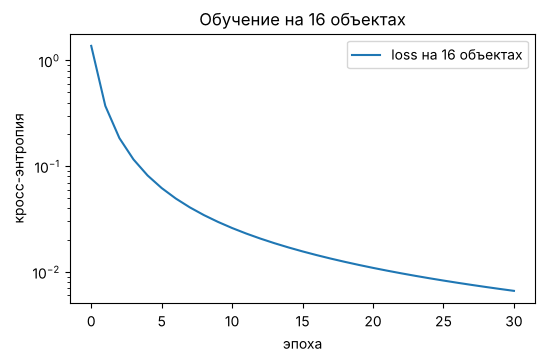

In [13]:
# Решение пункта 1.4.

# Свои тесты


def check_deep_network():
    """Сеть с двумя ReLU подряд, три класса, вход размерности 3.

    В проверке из задания скрытый слой один. Здесь градиент проходит через
    две маски ReLU и три линейных слоя.
    """
    rng = np.random.default_rng(201)
    layers = [Linear(3, 5, rng), ReLU(), Linear(5, 4, rng), ReLU(), Linear(4, 3, rng)]
    net = Sequential(*layers)
    X = rng.normal(size=(6, 3))
    y = np.array([0, 1, 2, 2, 1, 0])
    s1 = X @ layers[0].W + layers[0].b
    s2 = np.maximum(s1, 0.0) @ layers[2].W + layers[2].b
    # Численная производная верна только вдали от излома ReLU,
    # и обе маски должны действительно что-то обнулять
    assert min(np.abs(s1).min(), np.abs(s2).min()) > 1e-4
    assert (s1 < 0).any() and (s1 > 0).any() and (s2 < 0).any() and (s2 > 0).any()
    _, dlogits = softmax_cross_entropy(net.forward(X), y)
    dx = net.backward(dlogits).copy()
    grads = [g.copy() for g in net.gradients()]

    def objective():
        return softmax_cross_entropy(net.forward(X), y)[0]

    names = ["W1", "b1", "W2", "b2", "W3", "b3"]
    errors = {
        name: compare_gradients(g, numerical_gradient(objective, p))
        for name, p, g in zip(names, net.parameters(), grads)
    }
    errors["X"] = compare_gradients(dx, numerical_gradient(objective, X))
    return errors


def check_descent_step():
    """Малый шаг SGD уменьшает потерю на lr * |g|^2 по формуле Тейлора.

    Проверки из задания тестируют градиент и шаг SGD по отдельности,
    а этот тест проверяет, что они согласованы по знаку и масштабу.
    """
    model = make_mlp(hidden=8, seed=301)
    X = np.random.default_rng(302).normal(size=(10, 2))
    y = np.array([0, 1] * 5)
    loss_before, dlogits = softmax_cross_entropy(model.forward(X), y)
    model.backward(dlogits)
    squared_norm = sum(float(np.sum(g**2)) for g in model.gradients())
    lr = 1e-5
    SGD(model, lr).step()
    loss_after, _ = softmax_cross_entropy(model.forward(X), y)
    ratio = (loss_before - loss_after) / (lr * squared_norm)
    assert loss_after < loss_before
    assert abs(ratio - 1.0) < 1e-3, ratio
    return f"уменьшение loss относится к lr * |g|^2 как {ratio:.5f}"


def check_divergence_stops():
    """При огромном шаге обучение должно остановиться с FloatingPointError,
    а история до сбоя должна сохраниться. Это требование условия нигде не проверялось."""
    X, y, V, vy = _training_fixture()
    model = make_mlp(hidden=8, seed=303)
    try:
        fit(model, X, y, V, vy, epochs=50, lr=1e200, batch_size=2, shuffle_seed=19)
    except FloatingPointError as exc:
        history = exc.history
        assert len(history) >= 1 and np.all(np.isfinite(history.iloc[0, 1:]))
        return f"FloatingPointError после {len(history) - 1} завершённых эпох"
    raise AssertionError("Ожидалась FloatingPointError.")


checks_14 = run_checks(
    {
        "Свой тест, две ReLU и три класса": check_deep_network,
        "Свой тест, градиент и шаг SGD согласованы": check_descent_step,
        "Свой тест, остановка при расходимости": check_divergence_stops,
    }
)

# Таблица относительных ошибок аналитических градиентов
error_rows = []
for table in (checks_11, checks_12, checks_14):
    for _, row in table.iterrows():
        if row["статус"] == "OK" and isinstance(row["детали"], dict):
            for grad_name, value in row["детали"].items():
                error_rows.append(
                    {"проверка": row["проверка"], "градиент": grad_name, "отн. ошибка": value}
                )
gradient_errors = pd.DataFrame(error_rows)
with pd.option_context("display.float_format", "{:.2e}".format):
    display(gradient_errors)
all_checks = pd.concat([checks_11, checks_12, checks_13, checks_14], ignore_index=True)
assert (all_checks["статус"] == "OK").all()
print(f"Все {len(all_checks)} проверок прошли, максимальная относительная ошибка градиента "
      f"{gradient_errors['отн. ошибка'].max():.2e}")

# Обучение сети с 8 скрытыми нейронами на 16 объектах
sanity_model = make_mlp(hidden=8, seed=SEED)
sanity_W_init = [sanity_model.layers[0].W.copy(), sanity_model.layers[2].W.copy()]
sanity_history = fit(
    sanity_model, sanity_X, sanity_y, sanity_X, sanity_y,
    epochs=30, lr=0.1, batch_size=4, shuffle_seed=SHUFFLE_SEED,
)
first_row, last_row = sanity_history.iloc[0], sanity_history.iloc[-1]
sanity_summary = pd.DataFrame(
    [
        {
            "loss в начале": first_row["train_loss"],
            "loss в конце": last_row["train_loss"],
            "accuracy в начале": first_row["train_acc"],
            "accuracy в конце": last_row["train_acc"],
            "норма изменения W1": np.linalg.norm(sanity_model.layers[0].W - sanity_W_init[0]),
            "норма изменения W2": np.linalg.norm(sanity_model.layers[2].W - sanity_W_init[1]),
            "норма W1 в начале": np.linalg.norm(sanity_W_init[0]),
            "норма W2 в начале": np.linalg.norm(sanity_W_init[1]),
        }
    ],
    index=["MLP 8, ReLU, 30 эпох, lr 0.1, батч 4"],
)
display(sanity_summary)
assert last_row["train_acc"] == 1.0 and last_row["train_loss"] < first_row["train_loss"]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(sanity_history["epoch"], sanity_history["train_loss"], label="loss на 16 объектах")
ax.set(xlabel="эпоха", ylabel="кросс-энтропия", title="Обучение на 16 объектах", yscale="log")
ax.legend()
plt.show()


**Ответ:**

Все проверки из задания и три моих теста прошли со статусом OK. Относительная ошибка аналитических градиентов в проверках задания не превышает $4 \cdot 10^{-10}$, в моём тесте с двумя ReLU максимум $5.3 \cdot 10^{-9}$. Для центральной разности с шагом $10^{-6}$ это нормальный уровень, её погрешность складывается из члена порядка $\varepsilon^2$ и ошибки округления порядка $10^{-16}/\varepsilon$.

Свои тесты я добавил на то, что предоставленные проверки не покрывают. Первый проверяет сеть из трёх линейных слоёв с двумя ReLU и тремя классами, то есть что Sequential.backward правильно проводит градиент через несколько масок подряд. В проверке из задания скрытый слой только один. Второй тест проверяет, что градиент и шаг SGD согласованы между собой. По формуле Тейлора малый шаг уменьшает потерю на $\mathrm{lr} \cdot \|g\|^2$, и отношение настоящего уменьшения к этой величине получилось 0.99999, значит знак и масштаб обновления правильные. Третий тест проверяет требование из условия, которое нигде не тестировалось. При огромном шаге обучение должно остановиться с FloatingPointError, и история до сбоя должна сохраниться.

На 16 объектах сеть с 8 скрытыми нейронами за 30 эпох снизила loss с 1.37 до 0.0066, а accuracy выросла с 0 до 1. Второй слой изменился сильнее первого. Норма изменения W2 равна 1.75 при начальной норме 1.13, а у W1 изменение 0.60 при начальной норме 2.51. Так и должно быть, ведь выборка разделяется прямой и почти всю работу может сделать выходной слой.

Проверки подтверждают правильность формул обратного прохода, то что градиенты перезаписываются и не накапливаются, обновление параметров на месте, обработку последнего неполного батча, воспроизводимость при одинаковом shuffle_seed и независимость обучения от validation. Ограничения у них тоже есть. Градиенты сверяются в нескольких случайных точках маленькой размерности и вдали от излома ReLU, поэтому соглашение о производной в нуле численно не проверено. О качестве обучения на сложной задаче проверки ничего не говорят. А 16 объектов разделяются прямой, поэтому пользу скрытого слоя этот опыт не показывает, её видно в пункте 2.2 на circles.


## Задание 2. Исследование обучения

Используйте реализацию из задания 1. Даны два набора по 600 объектов:
гауссовские облака (`clouds`) и вложенные окружности (`circles`).
Стратифицированное разбиение на обучающую, валидационную и тестовую выборки
выполнено в пропорции 60 / 20 / 20. Параметры генерации и разбиение фиксированы.

**Протокол экспериментов.** Параметры предобработки и модели оценивайте только
по `train`, конфигурацию выбирайте по `validation`. К `test` обращайтесь
только в пункте 2.5. Во всех сравнениях сохраняйте выбранную предобработку,
число эпох и размер батча; если не оговорено иное, меняйте только исследуемый
параметр. Каждый запуск начинается с исходной инициализации.

До сравнений в пунктах 2.2–2.4 сформулируйте гипотезы. Сохраняйте настройки,
обученные модели и истории всех запусков, включая неудачные. Для завершившихся
запусков сравнивайте метрики последней эпохи. Полностью совпадающие запуски
можно использовать повторно. Заданного порога accuracy на этих данных нет.


In [14]:
def split_dataset(X: np.ndarray, y: np.ndarray) -> dict:
    idx_train, idx_hold = train_test_split(
        np.arange(len(y)), test_size=0.4, stratify=y, random_state=SEED
    )
    idx_valid, idx_test = train_test_split(
        idx_hold, test_size=0.5, stratify=y[idx_hold], random_state=SEED
    )
    assert not (
        set(idx_train) & set(idx_valid)
        or set(idx_train) & set(idx_test)
        or set(idx_valid) & set(idx_test)
    )
    result = {}
    for name, idx in [
        ("train", idx_train),
        ("valid", idx_valid),
        ("test", idx_test),
    ]:
        result[f"X_{name}"] = np.asarray(X[idx], dtype=np.float64)
        result[f"y_{name}"] = np.asarray(y[idx], dtype=np.int64)
    return result


data = {
    "clouds": split_dataset(
        *make_blobs(
            n_samples=600,
            centers=[[-2.0, -1.0], [2.0, 1.0]],
            cluster_std=0.9,
            random_state=SEED,
        )
    ),
    "circles": split_dataset(
        *make_circles(
            n_samples=600,
            factor=0.5,
            noise=0.12,
            random_state=SEED,
        )
    ),
}
for name, dataset in data.items():
    print(
        name,
        {
            part: len(dataset[f"y_{part}"])
            for part in ("train", "valid", "test")
        },
    )

clouds {'train': 360, 'valid': 120, 'test': 120}
circles {'train': 360, 'valid': 120, 'test': 120}


### 2.1. Данные и предобработка

Для обучающей части каждого набора представьте доли классов, диапазоны
признаков, число пропусков и дубликатов, а также диаграмму рассеяния
с обозначением классов.

Выберите и обоснуйте предобработку. Подготовленные данные сохраните
в `prepared`, сохранив структуру словаря `data`. Исходный `data` не изменяйте.
Если предобработка не требуется, сохраните в `prepared` копию исходных данных.

Для каждого набора оцените на validation accuracy классификатора,
предсказывающего наиболее частый класс train. При равенстве частот выберите
класс `0`. Сопоставьте геометрию наборов с возможностями линейной модели.


набор,clouds,circles
объектов,360.0000,360.0000
доля класса 0,0.5000,0.5000
доля класса 1,0.5000,0.5000
x1 min,-4.9171,-1.2049
x1 max,4.3160,1.1147
x2 min,-2.9900,-1.1999
x2 max,3.3691,1.2900
x1 mean,0.0559,0.0159
x2 mean,0.0923,0.0380
x1 std,2.2423,0.5694


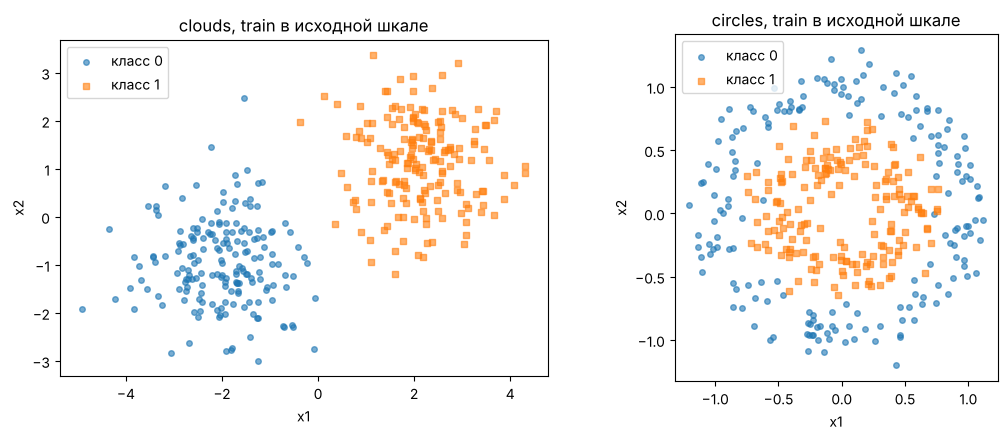

,clouds,circles
mean x1 по train,0.0559,0.0159
mean x2 по train,0.0923,0.038
std x1 по train,2.2423,0.5694
std x2 по train,1.3687,0.5583
std train после,[1. 1.],[1. 1.]
mean valid после,[-0.005 -0.158],[-0.043 -0.088]


собственные числа E[x x^T] число обусловленности доля нейронов, чья прямая проходит через train доля положительных входов ReLU
clouds  исходные признаки           [0.79 1.01 6.11]                7.7213                                            1.0                         0.5102
        стандартизация              [0.31 1.   1.69]                5.5079                                            1.0                         0.5095
circles исходные признаки           [0.31 0.33 1.  ]                3.2423                                         0.9375                         0.4875
        стандартизация              [0.98 1.   1.02]                1.0356                                            1.0                         0.5059

,класс 0 в train,класс 1 в train,предсказываемый класс,valid accuracy
набор,,,,
clouds,180,180,0,0.5
circles,180,180,0,0.5


In [15]:
# Решение пункта 2.1.
data_snapshot = copy.deepcopy(data)  # чтобы в конце убедиться, что data не изменился

# Описание обучающих частей
eda_rows = []
for name, ds in data.items():
    X, y = ds["X_train"], ds["y_train"]
    shares = np.bincount(y, minlength=2) / len(y)
    features = pd.DataFrame(X, columns=["x1", "x2"])
    eda_rows.append(
        {
            "набор": name,
            "объектов": len(y),
            "доля класса 0": shares[0],
            "доля класса 1": shares[1],
            "x1 min": X[:, 0].min(),
            "x1 max": X[:, 0].max(),
            "x2 min": X[:, 1].min(),
            "x2 max": X[:, 1].max(),
            "x1 mean": X[:, 0].mean(),
            "x2 mean": X[:, 1].mean(),
            "x1 std": X[:, 0].std(),
            "x2 std": X[:, 1].std(),
            "пропусков": int(np.isnan(X).sum()),
            "дубликатов X": int(features.duplicated().sum()),
            "дубликатов X и y": int(features.assign(y=y).duplicated().sum()),
        }
    )
eda_table = pd.DataFrame(eda_rows).set_index("набор")
display(eda_table.T)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, ds) in zip(axes, data.items()):
    X, y = ds["X_train"], ds["y_train"]
    for label, marker in [(0, "o"), (1, "s")]:
        ax.scatter(*X[y == label].T, marker=marker, s=16, alpha=0.6, label=f"класс {label}")
    ax.set(title=f"{name}, train в исходной шкале", xlabel="x1", ylabel="x2")
    ax.set_aspect("equal")
    ax.legend()
fig.tight_layout()
plt.show()


# Стандартизация. Среднее и стандартное отклонение считаются только по train
# и потом без пересчёта применяются к valid и test.
def standardize(dataset: dict) -> tuple[dict, np.ndarray, np.ndarray]:
    mean = dataset["X_train"].mean(axis=0)
    std = dataset["X_train"].std(axis=0)
    result = {}
    for part in ("train", "valid", "test"):
        result[f"X_{part}"] = (dataset[f"X_{part}"] - mean) / std
        result[f"y_{part}"] = dataset[f"y_{part}"].copy()
    return result, mean, std


prepared, scaling = {}, {}
for name, ds in data.items():
    prepared[name], mean, std = standardize(ds)
    scaling[name] = {"mean": mean, "std": std}

scaling_table = pd.DataFrame(
    {
        name: {
            "mean x1 по train": s["mean"][0],
            "mean x2 по train": s["mean"][1],
            "std x1 по train": s["std"][0],
            "std x2 по train": s["std"][1],
            "std train после": str(np.round(prepared[name]["X_train"].std(axis=0), 4)),
            "mean valid после": str(np.round(prepared[name]["X_valid"].mean(axis=0), 3)),
        }
        for name, s in scaling.items()
    }
)
display(scaling_table)


# Что стандартизация меняет для обучения, смотрим до всякого обучения.
# 1. Для линейной модели гессиан кросс-энтропии в нуле пропорционален матрице E[x x^T],
#    где к признакам добавлена единица. Отношение её крайних собственных чисел показывает,
#    насколько по-разному искривлена функция потерь по разным направлениям.
# 2. Нейрон первого слоя делит плоскость прямой w x + b = 0. Если эта прямая не проходит
#    через облако train, нейрон в начале обучения почти бесполезен для построения границы.
def init_diagnostics(X: np.ndarray, hidden: int = 16, seed: int = SEED) -> dict:
    X_aug = np.column_stack([X, np.ones(len(X))])
    eig = np.linalg.eigvalsh(X_aug.T @ X_aug / len(X))
    first = make_mlp(hidden=hidden, seed=seed).layers[0]
    pre = X @ first.W + first.b
    crossing = np.mean((pre > 0).any(axis=0) & (pre < 0).any(axis=0))
    return {
        "собственные числа E[x x^T]": np.array2string(eig, precision=2),
        "число обусловленности": eig.max() / eig.min(),
        "доля нейронов, чья прямая проходит через train": crossing,
        "доля положительных входов ReLU": np.mean(pre > 0),
    }


diag_rows = {}
for name in data:
    diag_rows[(name, "исходные признаки")] = init_diagnostics(data[name]["X_train"])
    diag_rows[(name, "стандартизация")] = init_diagnostics(prepared[name]["X_train"])
display(pd.DataFrame(diag_rows).T)

# Структура prepared совпадает с data, исходный data не изменился
for name in data:
    assert prepared[name].keys() == data[name].keys()
    for key in data[name]:
        assert prepared[name][key].dtype == data[name][key].dtype
        np.testing.assert_array_equal(data[name][key], data_snapshot[name][key])

# Константный классификатор
baseline_rows = []
for name, ds in prepared.items():
    counts = np.bincount(ds["y_train"], minlength=2)
    majority = int(np.argmax(counts))  # при равенстве argmax возвращает первый индекс, то есть 0
    baseline_rows.append(
        {
            "набор": name,
            "класс 0 в train": counts[0],
            "класс 1 в train": counts[1],
            "предсказываемый класс": majority,
            "valid accuracy": float(np.mean(ds["y_valid"] == majority)),
        }
    )
baseline = pd.DataFrame(baseline_rows).set_index("набор")
display(baseline)


**Ответ:**

Обе обучающие части сбалансированы, в каждой по 180 объектов каждого класса, пропусков и дубликатов нет. У clouds первый признак лежит примерно от $-4.9$ до $4.3$, второй от $-3.0$ до $3.4$, стандартные отклонения 2.24 и 1.37. У circles оба признака примерно от $-1.2$ до $1.3$, стандартное отклонение около 0.56.

В качестве предобработки я выбрал стандартизацию. Среднее и стандартное отклонение считаются только по train, и то же самое преобразование применяется к validation и test. Если считать их по всем данным, преобразование заранее увидит объекты, на которых модель потом проверяется.

Доводов за стандартизацию два, и оба получены до обучения. Первый связан с инициализацией. Она рассчитана на признаки единичного масштаба, веса имеют дисперсию $1/n_{in}$, а смещения лежат в пределах $\pm 1/\sqrt{n_{in}}$. На circles в исходной шкале одна из 16 прямых первого слоя вообще не проходит через данные, а после стандартизации через данные проходят все. Второй довод про обусловленность. У линейной модели гессиан кросс-энтропии в нуле пропорционален матрице $E[\tilde x \tilde x^T]$, где $\tilde x = (x_1, x_2, 1)$. Стандартизация уменьшает её число обусловленности с 3.24 до 1.04 на circles и с 7.7 до 5.5 на clouds. На clouds оно остаётся большим, потому что признаки там коррелированы, центры облаков лежат на прямой $x_2 = x_1 / 2$. Стандартизация выравнивает масштаб, но корреляцию не убирает. При этом аффинное преобразование не меняет набор границ, которые может построить модель, оно влияет только на ход оптимизации. Отдельно я проверил этот выбор опытом сразу после пункта 2.2.

Константный классификатор при равных частотах предсказывает класс 0 и получает на validation accuracy 0.5 на обоих наборах. Облака разделяются прямой почти без ошибок. Расстояние между центрами 4.47 при $\sigma = 0.9$, и у оптимального правила ошибка около 0.7%. Окружности прямой не разделить, потому что любая прямая режет каждое кольцо на две части, так что линейная модель не может быть заметно лучше константы. Класс здесь определяется радиусом, и нужен либо признак вроде $x_1^2 + x_2^2$, либо скрытый слой, который построит такой признак сам.


Функция `plot_boundary` строит разделяющую границу модели, обучающие объекты
и ошибки на validation. Аргументы должны быть представлены в той же шкале,
в которой обучалась модель.


In [16]:
def plot_boundary(
    model: Module,
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_valid: np.ndarray,
    y_valid: np.ndarray,
    title: str,
):
    low, high = X_train.min(axis=0) - 0.4, X_train.max(axis=0) + 0.4
    xx, yy = np.meshgrid(
        np.linspace(low[0], high[0], 160), np.linspace(low[1], high[1], 160)
    )
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    grid_logits = model.forward(grid)
    score = (grid_logits[:, 1] - grid_logits[:, 0]).reshape(xx.shape)
    fig, ax = plt.subplots(figsize=(6, 5))
    if score.min() < 0 < score.max():
        ax.contour(xx, yy, score, levels=[0.0], linewidths=1.6)
    for label, marker in [(0, "o"), (1, "s")]:
        mask = y_train == label
        ax.scatter(
            X_train[mask, 0],
            X_train[mask, 1],
            marker=marker,
            s=18,
            alpha=0.5,
            label=f"train: класс {label}",
        )
    wrong = model.forward(X_valid).argmax(axis=1) != y_valid
    if np.any(wrong):
        ax.scatter(
            X_valid[wrong, 0],
            X_valid[wrong, 1],
            marker="x",
            s=42,
            label="ошибка validation",
        )
    ax.set(
        title=title,
        xlabel="x1 (рабочая шкала)",
        ylabel="x2 (рабочая шкала)",
        xlim=(low[0], high[0]),
        ylim=(low[1], high[1]),
    )
    ax.legend()
    fig.tight_layout()
    plt.show()

### 2.2. Линейная модель и сеть со скрытым слоем

На каждом наборе обучите линейный классификатор `make_linear()` и сеть
`make_mlp(hidden=16)` с ReLU — всего четыре модели.
Используйте `seed=SEED`, `shuffle_seed=SHUFFLE_SEED` и единый режим обучения:
`epochs=200`, `lr=0.1`, `batch_size=32`.

Представьте таблицу train/validation loss и accuracy для четырёх моделей.
Для окружностей постройте кривые train/validation loss и разделяющие границы
обеих моделей.

Объясните различия результатов с учётом геометрии данных, выразительности
моделей и хода оптимизации.


**Гипотеза:**

На clouds линейная модель и сеть дадут почти одинаковую accuracy, около 0.98 или 0.99, потому что классы разделяются прямой и скрытому слою нечего добавить. У сети train loss при этом уйдёт почти в ноль, и valid loss может начать расти, ведь на разделимых данных кросс-энтропию можно уменьшать бесконечно, просто увеличивая веса. На circles линейная модель останется на уровне константы, с accuracy около 0.5 и loss около $\ln 2 \approx 0.69$. Сеть с 16 нейронами ReLU построит замкнутую многоугольную границу вокруг внутреннего кольца и получит accuracy не ниже 0.95.


,набор,модель,предобработка,seed,lr,эпох,batch,статус,train loss,valid loss,train acc,valid acc
0,clouds,"Linear(2, 2)",стандартизация,42,0.1,200,32,завершён,0.0097,0.0445,1.0000,0.9833
1,clouds,"MLP 16, ReLU",стандартизация,42,0.1,200,32,завершён,0.0015,0.0577,1.0000,0.9833
2,circles,"Linear(2, 2)",стандартизация,42,0.1,200,32,завершён,0.6930,0.6934,0.5056,0.5167
3,circles,"MLP 16, ReLU",стандартизация,42,0.1,200,32,завершён,0.0664,0.0605,0.9806,0.9833


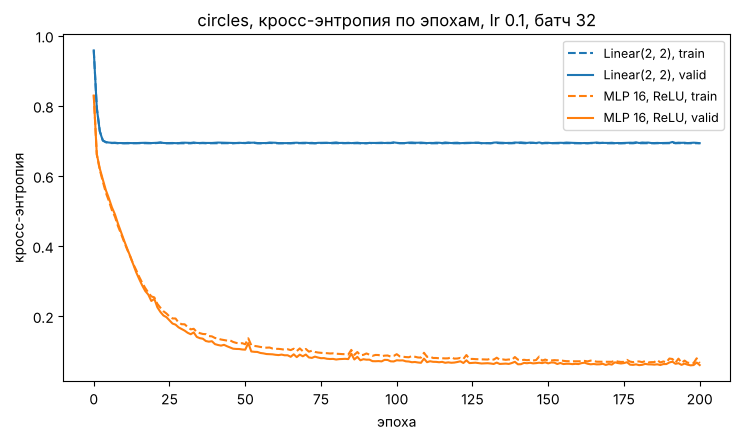

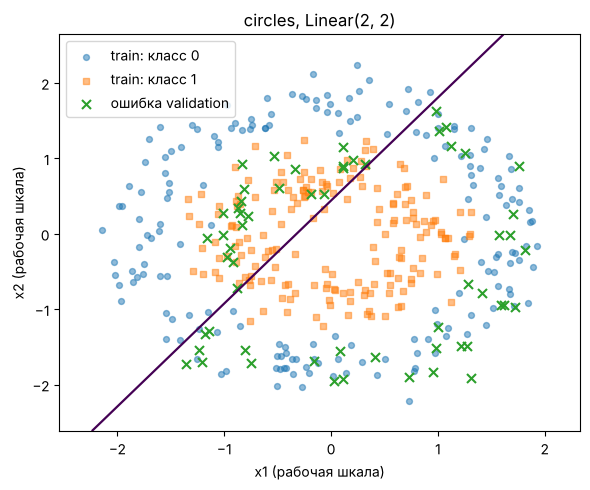

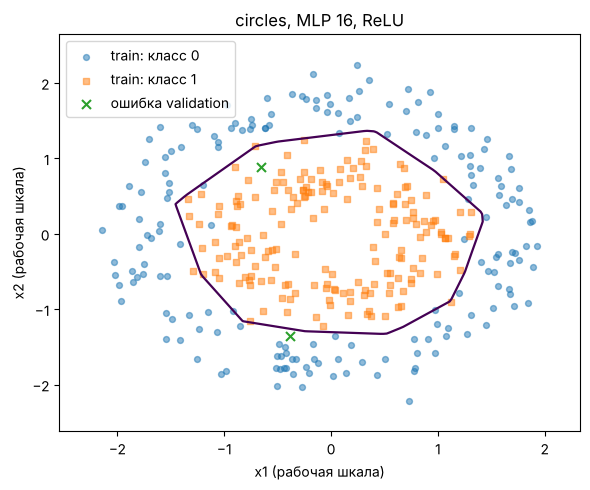

In [17]:
# Решение пункта 2.2.

# Общий режим обучения для всех сравнений задания 2
TRAINING = {"epochs": 200, "batch_size": 32, "shuffle_seed": SHUFFLE_SEED}

# Здесь хранятся все запуски. Ключ содержит полную конфигурацию, а значение хранит модель,
# начальные параметры, историю и статус. Совпадающая конфигурация повторно не обучается.
runs = {}


def run_config(dataset, kind, hidden=None, activation=None, seed=SEED, lr=0.1, prep="std"):
    """prep='std' берёт стандартизованные данные из prepared, prep='raw' исходные из data."""
    key = (dataset, kind, hidden, activation, seed, lr, prep,
           TRAINING["epochs"], TRAINING["batch_size"], TRAINING["shuffle_seed"])
    if key in runs:
        return runs[key]
    model = make_linear(seed) if kind == "linear" else make_mlp(hidden, activation, seed)
    initial = [p.copy() for p in model.parameters()]
    ds = prepared[dataset] if prep == "std" else data[dataset]
    try:
        history = fit(model, ds["X_train"], ds["y_train"], ds["X_valid"], ds["y_valid"],
                      lr=lr, **TRAINING)
        status = "завершён"
    except FloatingPointError as exc:
        history = exc.history
        status = f"расходимость, {exc}"
    runs[key] = {
        "config": {
            "набор": dataset,
            "модель": "Linear(2, 2)" if kind == "linear"
                      else f"MLP {hidden}, {'ReLU' if activation == 'relu' else 'Step'}",
            "ширина": hidden if hidden is not None else 0,
            "активация": activation or "нет",
            "предобработка": "стандартизация" if prep == "std" else "нет",
            "seed": seed,
            "lr": lr,
            "эпох": TRAINING["epochs"],
            "batch": TRAINING["batch_size"],
        },
        "model": model,
        "initial": initial,
        "history": history,
        "status": status,
    }
    return runs[key]


def dead_units(record) -> int:
    """Сколько скрытых нейронов ReLU не активны ни на одном объекте train."""
    model = record["model"]
    if len(model.layers) != 3 or not isinstance(model.layers[1], ReLU):
        return np.nan
    source = prepared if record["config"]["предобработка"] == "стандартизация" else data
    pre = source[record["config"]["набор"]]["X_train"] @ model.layers[0].W + model.layers[0].b
    return int(np.all(pre <= 0.0, axis=0).sum())


def summary_row(record, tail: int = 20) -> dict:
    hist = record["history"]
    last = hist.iloc[-1]
    best = hist.loc[hist["valid_loss"].idxmin()]
    window = hist["valid_loss"].iloc[-tail:]  # последние эпохи, чтобы оценить шум
    return {
        **record["config"],
        "статус": record["status"],
        "train loss": last["train_loss"],
        "valid loss": last["valid_loss"],
        "train acc": last["train_acc"],
        "valid acc": last["valid_acc"],
        "min valid loss": best["valid_loss"],
        "эпоха min valid loss": int(best["epoch"]),
        f"valid loss, среднее за {tail} эп.": window.mean(),
        f"valid loss, std за {tail} эп.": window.std(ddof=1),
    }


def plot_loss_curves(items, title, logy=False):
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    for label, record in items:
        hist = record["history"]
        (line,) = ax.plot(hist["epoch"], hist["train_loss"], linestyle="--", label=f"{label}, train")
        ax.plot(hist["epoch"], hist["valid_loss"], color=line.get_color(), label=f"{label}, valid")
    ax.set(xlabel="эпоха", ylabel="кросс-энтропия", title=title)
    if logy:
        ax.set_yscale("log")
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()


results_22 = {
    (name, kind): run_config(name, kind, hidden=16 if kind == "mlp" else None,
                             activation="relu" if kind == "mlp" else None, lr=0.1)
    for name in ("clouds", "circles")
    for kind in ("linear", "mlp")
}
table_22 = pd.DataFrame([summary_row(r) for r in results_22.values()])
display(table_22[["набор", "модель", "предобработка", "seed", "lr", "эпох", "batch", "статус",
                  "train loss", "valid loss", "train acc", "valid acc"]])

c = prepared["circles"]
plot_loss_curves(
    [("Linear(2, 2)", results_22[("circles", "linear")]),
     ("MLP 16, ReLU", results_22[("circles", "mlp")])],
    "circles, кросс-энтропия по эпохам, lr 0.1, батч 32",
)
for kind, label in [("linear", "Linear(2, 2)"), ("mlp", "MLP 16, ReLU")]:
    plot_boundary(results_22[("circles", kind)]["model"], c["X_train"], c["y_train"],
                  c["X_valid"], c["y_valid"], f"circles, {label}")


**Обсуждение результатов:**

На clouds обе модели дали на validation 0.983, то есть ошиблись на двух объектах из 120, и скрытый слой ничего не добавил. Зато у сети train loss 0.0015 против 0.0097 у линейной модели, а valid loss хуже, 0.058 против 0.045. Минимум valid loss у сети был ещё на эпохе 29 и равнялся 0.046. Так кросс-энтропия и ведёт себя на разделимых данных. Все объекты train уже классифицированы верно, SGD продолжает увеличивать веса, уверенность модели растёт, а вместе с ней растёт и штраф за два неверных объекта validation. Accuracy от этого не меняется, а loss замечает.

На circles линейная модель застряла на loss 0.693, это почти ровно $\ln 2$, и accuracy 0.517, то есть на уровне константы. Для симметричных колец любая прямая одинаково плоха, оптимум линейной модели находится около нулевых весов, и логиты почти не отличаются от нуля. Сеть с 16 нейронами получила 0.983 при valid loss 0.061. На графике её граница выглядит как многоугольник вокруг внутреннего кольца. Сеть с ReLU задаёт кусочно линейную функцию, и 16 линий излома хватает, чтобы приблизить окружность. Кривые train и valid loss у сети почти совпадают на всём обучении, переобучения не видно, а к эпохе 200 loss ещё медленно снижается. Гипотеза подтвердилась полностью, включая рост valid loss у сети на clouds.


### Дополнительно к 2.2. Проверка выбранной предобработки

В пункте 2.1 стандартизацию я выбрал до обучения, по статистикам train. Здесь я проверяю этот выбор опытом. Те же четыре модели из 2.2 обучаются на исходных признаках в том же режиме (seed 42, lr 0.1, 200 эпох, батч 32), а сравнение идёт по validation. Test здесь не используется, и после этого опыта выбор предобработки я не менял.


,набор,модель,предобработка,статус,train loss,valid loss,train acc,valid acc,min valid loss,эпоха min valid loss
0,clouds,"Linear(2, 2)",стандартизация,завершён,0.0097,0.0445,1.0000,0.9833,0.0445,200
1,clouds,"Linear(2, 2)",нет,завершён,0.0034,0.0493,1.0000,0.9750,0.0464,61
2,clouds,"MLP 16, ReLU",стандартизация,завершён,0.0015,0.0577,1.0000,0.9833,0.0458,29
3,clouds,"MLP 16, ReLU",нет,завершён,0.0007,0.0651,1.0000,0.9833,0.0453,15
4,circles,"Linear(2, 2)",стандартизация,завершён,0.6930,0.6934,0.5056,0.5167,0.6932,90
5,circles,"Linear(2, 2)",нет,завершён,0.6930,0.6938,0.5028,0.5083,0.6933,13
6,circles,"MLP 16, ReLU",стандартизация,завершён,0.0664,0.0605,0.9806,0.9833,0.0596,197
7,circles,"MLP 16, ReLU",нет,завершён,0.0705,0.0674,0.9861,0.9833,0.0668,197


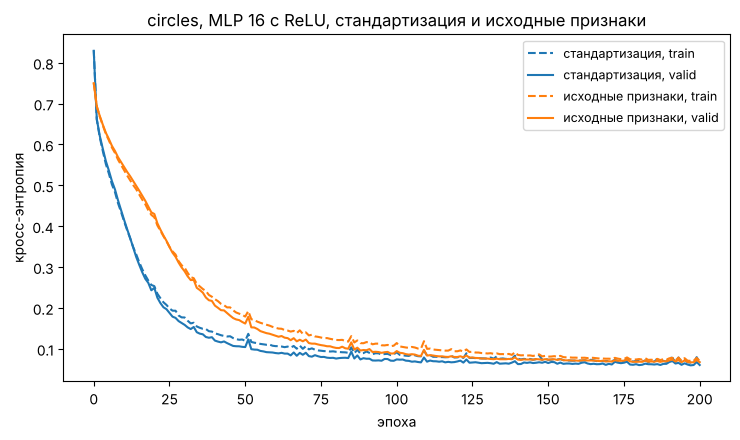

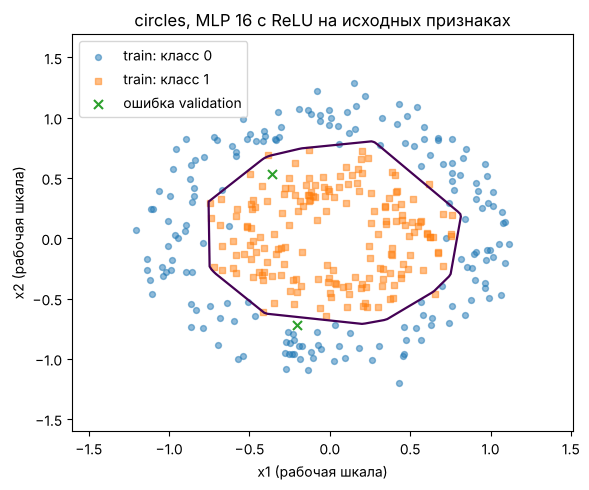

In [18]:
# Те же четыре модели из 2.2 на исходных признаках
prep_rows = []
for name in ("clouds", "circles"):
    for kind in ("linear", "mlp"):
        params = {"hidden": 16, "activation": "relu"} if kind == "mlp" else {}
        for prep in ("std", "raw"):
            prep_rows.append(summary_row(run_config(name, kind, lr=0.1, prep=prep, **params)))
table_prep = pd.DataFrame(prep_rows)
display(table_prep[["набор", "модель", "предобработка", "статус", "train loss", "valid loss",
                    "train acc", "valid acc", "min valid loss", "эпоха min valid loss"]])

circles_raw = run_config("circles", "mlp", hidden=16, activation="relu", lr=0.1, prep="raw")
plot_loss_curves(
    [("стандартизация", run_config("circles", "mlp", hidden=16, activation="relu", lr=0.1)),
     ("исходные признаки", circles_raw)],
    "circles, MLP 16 с ReLU, стандартизация и исходные признаки",
)
raw = data["circles"]
plot_boundary(circles_raw["model"], raw["X_train"], raw["y_train"], raw["X_valid"], raw["y_valid"],
              "circles, MLP 16 с ReLU на исходных признаках")


Стандартизация оказалась не хуже исходных признаков во всех четырёх случаях. Сильнее всего это видно по valid loss сетей, 0.058 против 0.065 на clouds и 0.061 против 0.067 на circles при одинаковой accuracy 0.983. У линейной модели на clouds с исходными признаками train loss даже ниже, 0.0034 против 0.0097, но valid loss выше, 0.049 против 0.045, и accuracy 0.975 против 0.983. В исходной шкале признаки clouds крупнее, поэтому при том же шаге логиты растут быстрее и модель раньше становится слишком уверенной. Линейной модели на circles предобработка не помогает, ей нечего выучить ни в какой шкале. Разница небольшая, но направление совпадает с доводами из 2.1, поэтому стандартизацию я оставил.


### 2.3. Ширина сети и шаг обучения

На наборе `circles` исследуйте сеть с ReLU в двух последовательных сериях.
Используйте `seed=SEED`, `shuffle_seed=SHUFFLE_SEED`, `epochs=200`
и `batch_size=32`.

**Серия A.** Сравните ширины скрытого слоя `4, 16, 64` при `lr=0.1`.
Постройте зависимость конечных train/validation loss от ширины и выберите
ширину по validation.

**Серия B.** Для выбранной ширины сравните шаги `0.01, 0.1, 0.5`.
Начальные параметры и порядок батчей должны совпадать во всех трёх запусках.
Постройте кривые train/validation loss по эпохам и выберите шаг по validation.

Сведите настройки и конечные метрики двух серий в общую таблицу.
Всего в сериях пять различных конфигураций; совпадающий запуск из пункта 2.2
можно использовать повторно. Расходящиеся запуски отметьте отдельно;
при необходимости допустим один дополнительный диагностический запуск.

Обсудите влияние ширины и шага на результаты. Обоснуйте, позволяют ли
наблюдения судить о недообучении, переобучении и устойчивости оптимизации.


**Серия A. Гипотеза:**

У сети с 4 нейронами всего четыре линии излома, поэтому граница выйдет грубым многоугольником, и loss на train и на validation будет заметно выше. Между шириной 16 и 64 разница будет маленькой. Шестнадцати нейронов уже хватает на достаточно гладкий многоугольник, а на 360 объектах за 200 эпох переобучение широкой сети вряд ли успеет проявиться. Возможно, у ширины 64 train loss будет чуть ниже при таком же valid loss.


,модель,lr,статус,train loss,valid loss,train acc,valid acc,min valid loss,эпоха min valid loss,"valid loss, среднее за 20 эп.","valid loss, std за 20 эп.",мёртвых нейронов
0,"MLP 4, ReLU",0.1,завершён,0.1120,0.0943,0.9611,0.9583,0.0943,200,0.0976,0.0021,0
1,"MLP 16, ReLU",0.1,завершён,0.0664,0.0605,0.9806,0.9833,0.0596,197,0.0632,0.0028,0
2,"MLP 64, ReLU",0.1,завершён,0.0575,0.0611,0.9889,0.9833,0.0593,169,0.0631,0.0025,1


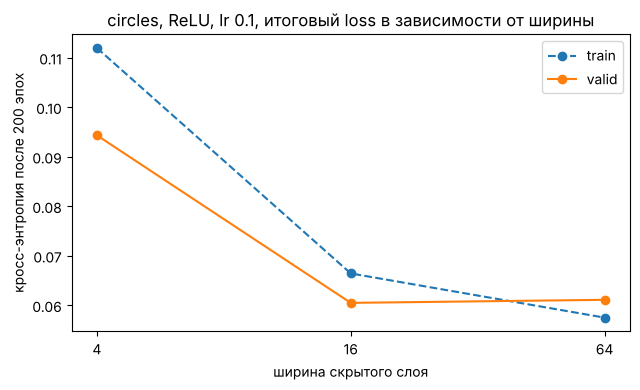

По valid loss выбрана ширина 16


In [19]:
# Серия A.
widths = [4, 16, 64]
series_a = {h: run_config("circles", "mlp", hidden=h, activation="relu", lr=0.1) for h in widths}
table_a = pd.DataFrame([{**summary_row(r), "мёртвых нейронов": dead_units(r)}
                        for r in series_a.values()])
display(table_a[["модель", "lr", "статус", "train loss", "valid loss", "train acc",
                 "valid acc", "min valid loss", "эпоха min valid loss",
                 "valid loss, среднее за 20 эп.", "valid loss, std за 20 эп.", "мёртвых нейронов"]])

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(widths, table_a["train loss"], marker="o", linestyle="--", label="train")
ax.plot(widths, table_a["valid loss"], marker="o", label="valid")
ax.set_xscale("log", base=2)
ax.set_xticks(widths, [str(h) for h in widths])
ax.set(xlabel="ширина скрытого слоя", ylabel="кросс-энтропия после 200 эпох",
       title="circles, ReLU, lr 0.1, итоговый loss в зависимости от ширины")
ax.legend()
fig.tight_layout()
plt.show()

# Выбираем по наименьшему valid loss в последней эпохе среди завершившихся запусков
finished_a = [h for h in widths if series_a[h]["status"] == "завершён"]
best_width = min(finished_a, key=lambda h: series_a[h]["history"].iloc[-1]["valid_loss"])
print(f"По valid loss выбрана ширина {best_width}")


**Серия B. Выбор ширины и гипотеза:**

По последней эпохе valid loss меньше всего у ширины 16, 0.0605 против 0.0611 у ширины 64, её я и беру. По сути 16 и 64 неразличимы. Средние valid loss за последние 20 эпох равны 0.0632 и 0.0631, а от эпохи к эпохе значения колеблются примерно на 0.003, то есть на порядок сильнее, чем различаются сами ширины. При равном качестве лучше взять меньшую сеть, у неё 82 параметра вместо 322.

Про шаг я ожидаю следующее. При lr 0.01 обучение будет слишком медленным, за 200 эпох сеть не доучится, и loss останется заметно выше. При lr 0.5 loss сначала упадёт быстрее, но потом начнёт сильно скакать. С постоянным шагом SGD не сходится к минимуму, а колеблется вокруг него, и чем больше шаг, тем больше размах колебаний. Если шаг окажется больше порога устойчивости, который порядка $2 / \lambda_{\max}$ гессиана, обучение может и разойтись. Лучшим по validation я ожидаю lr 0.1.


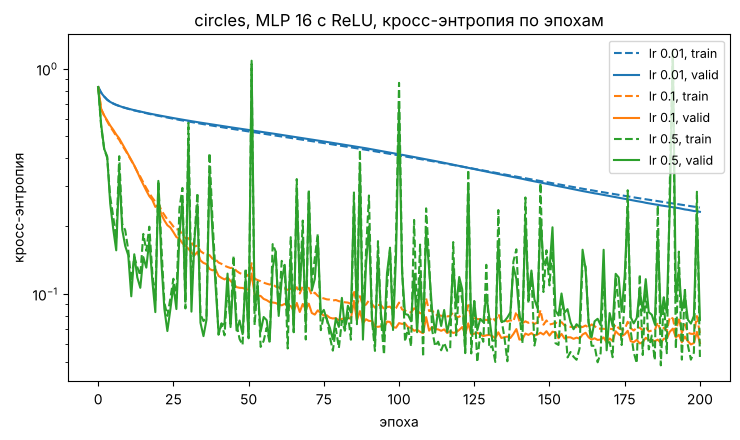

По valid loss выбран шаг 0.1


,серия,модель,ширина,lr,эпох,batch,статус,расходится,train loss,valid loss,train acc,valid acc,min valid loss,эпоха min valid loss,"valid loss, среднее за 20 эп.","valid loss, std за 20 эп.",мёртвых нейронов
0,A,"MLP 4, ReLU",4,0.10,200,32,завершён,False,0.1120,0.0943,0.9611,0.9583,0.0943,200,0.0976,0.0021,0
1,A,"MLP 16, ReLU",16,0.10,200,32,завершён,False,0.0664,0.0605,0.9806,0.9833,0.0596,197,0.0632,0.0028,0
2,A,"MLP 64, ReLU",64,0.10,200,32,завершён,False,0.0575,0.0611,0.9889,0.9833,0.0593,169,0.0631,0.0025,1
3,B,"MLP 16, ReLU",16,0.01,200,32,завершён,False,0.2419,0.2314,0.9639,0.9667,0.2314,200,0.2431,0.0074,0
4,B,"MLP 16, ReLU",16,0.50,200,32,завершён,False,0.0525,0.0766,0.9806,0.9833,0.0561,169,0.1637,0.2510,0


Для пунктов 2.4 и 2.5 берём ширину 16 и шаг 0.1


In [20]:
# Серия B.
learning_rates = [0.01, 0.1, 0.5]
series_b = {
    lr: run_config("circles", "mlp", hidden=best_width, activation="relu", lr=lr)
    for lr in learning_rates
}
# Один и тот же seed даёт одинаковые начальные параметры, а один и тот же shuffle_seed
# при том же размере train даёт одинаковый порядок батчей
reference = series_b[learning_rates[0]]["initial"]
for lr in learning_rates[1:]:
    assert all(np.array_equal(a, b) for a, b in zip(series_b[lr]["initial"], reference))

plot_loss_curves(
    [(f"lr {lr}", series_b[lr]) for lr in learning_rates],
    f"circles, MLP {best_width} с ReLU, кросс-энтропия по эпохам",
    logy=True,
)

finished_b = [lr for lr in learning_rates if series_b[lr]["status"] == "завершён"]
best_lr = min(finished_b, key=lambda lr: series_b[lr]["history"].iloc[-1]["valid_loss"])
print(f"По valid loss выбран шаг {best_lr}")

# Общая таблица двух серий, в ней пять разных конфигураций
summary_23 = []
for h in widths:
    summary_23.append({"серия": "A", **summary_row(series_a[h]),
                       "мёртвых нейронов": dead_units(series_a[h])})
for lr in learning_rates:
    if lr == 0.1:
        continue  # эта конфигурация уже есть в серии A
    summary_23.append({"серия": "B", **summary_row(series_b[lr]),
                       "мёртвых нейронов": dead_units(series_b[lr])})
table_23 = pd.DataFrame(summary_23)
table_23["расходится"] = table_23["статус"] != "завершён"
display(table_23[["серия", "модель", "ширина", "lr", "эпох", "batch", "статус", "расходится",
                  "train loss", "valid loss", "train acc", "valid acc",
                  "min valid loss", "эпоха min valid loss",
                  "valid loss, среднее за 20 эп.", "valid loss, std за 20 эп.", "мёртвых нейронов"]])
print(f"Для пунктов 2.4 и 2.5 берём ширину {best_width} и шаг {best_lr}")


**Обсуждение результатов и выбранные настройки:**

Сначала о ширине. Сеть с 4 нейронами заметно хуже, у неё valid loss 0.094 и accuracy 0.958, и train loss тоже высокий, 0.112. Это недообучение из-за малой выразительности, а не переобучение. Между шириной 16 и 64 разницы нет в пределах шума. У ширины 64 train loss чуть ниже, 0.058 против 0.066, и это единственный намёк на больший запас ёмкости, но на valid loss он не сказался. Переобучения не видно ни у одной ширины. К концу обучения valid loss не растёт, у ширины 16 минимум приходится на эпоху 197. Чтобы переобучение проявилось, нужна выборка поменьше или обучение подольше.

Теперь о шаге. При lr 0.01 к эпохе 200 loss равен 0.24 на train и 0.23 на validation и всё ещё ровно падает. Это недообучение из-за нехватки шагов, а не из-за модели, ведь та же сеть при lr 0.1 доходит до 0.06. При lr 0.5 обучение не разошлось, но кривые в резких выбросах примерно до 1.0. Среднее valid loss за последние 20 эпох у него 0.164 при стандартном отклонении 0.251, а у lr 0.1 эти числа 0.063 и 0.003. Это шум SGD с большим постоянным шагом. На семинаре 2 для выпуклой задачи выведена оценка, которая при постоянном шаге $\alpha$ принимает вид $\frac{R^2}{2 \alpha K} + \frac{\alpha G^2}{2}$. Первое слагаемое отвечает за скорость и уменьшается с ростом шага, второе задаёт уровень шума и растёт вместе с ним, и lr 0.1 оказался компромиссом. Последняя эпоха у lr 0.5 даёт 0.077, но это удачное совпадение. Его минимум 0.056 на эпохе 169 даже лучше, чем у lr 0.1, только поймать его без ранней остановки нельзя. Гипотеза подтвердилась во всём, кроме расходимости. При шаге 0.5 обучение шумит, но не разваливается, то есть порог устойчивости для этой сети выше 0.5.

Про устойчивость оптимизации эти опыты позволяют судить уверенно, а про переобучение только в пределах 200 эпох. Все сравнения сделаны при одном seed, поэтому различия valid loss меньше примерно 0.003 я считаю шумом.

В итоге выбраны ширина 16, lr 0.1, стандартизация, 200 эпох и батч 32.


### 2.4. Функция активации и обучение скрытого слоя

Сравните ReLU с предоставленной пороговой активацией `Step`:

$$
\operatorname{Step}(x) =
\begin{cases}
1, & x > 0, \\
0, & x \leq 0.
\end{cases}
$$

В её обратном проходе используется нулевая производная; в точке разрыва
это соглашение реализации. Реализацию `Step` изменять нельзя.
Используйте `circles` и выбранные в пункте 2.3 ширину и шаг обучения.

**Диагностика одного обновления.** Создайте сети с ReLU и Step при `seed=SEED`.
Начальные параметры должны попарно совпадать по значениям, но храниться
в независимых массивах. Выполните по одному шагу SGD на первых 32 объектах
train в порядке хранения. Для каждой сети представьте loss до и после шага,
нормы градиентов `W1`, `b1`, `W2`, `b2` перед обновлением
и нормы изменения этих параметров после обновления.

**Полное обучение.** Обучите обе архитектуры заново для инициализаций
`42, 43, 44` — всего шесть запусков. В каждой паре начальные параметры
должны совпадать. Шаг, ширина, число эпох, размер и порядок батчей одинаковы
во всех запусках; отдельно настраивать Step не требуется.

Представьте:

- таблицу train/validation loss и accuracy всех шести запусков и норм
  изменения матрицы весов первого слоя;
- среднее и выборочное стандартное отклонение validation accuracy
  по трём инициализациям для каждой активации (`ddof=1`);
- кривые train/validation loss и разделяющие границы двух моделей
  с `seed=SEED`.

Объясните связь между градиентами, изменением параметров и качеством моделей.
Оцените чувствительность результатов к инициализации и сформулируйте
ограничения сравнения активаций при общем режиме обучения.


In [21]:
class Step(Module):
    """Пороговая активация с нулевым градиентом в обратном проходе."""

    def forward(self, X: np.ndarray) -> np.ndarray:
        return (X > 0).astype(np.float64)

    def backward(self, grad_output: np.ndarray) -> np.ndarray:
        return np.zeros_like(grad_output)

**Гипотеза:**

У Step производная почти везде равна нулю, поэтому при обратном проходе градиент до первого слоя не доходит. Градиенты по W1 и b1 будут ровно нулевыми, и первый слой за всё обучение не изменится. Тогда сеть со Step превращается в линейный классификатор над 16 фиксированными бинарными признаками $[w_h^T x + b_h > 0]$, которые задала случайная инициализация. Такими признаками окружность можно приблизить только грубо, поэтому accuracy будет заметно ниже, чем у ReLU, примерно от 0.7 до 0.85. Ещё я жду сильной зависимости от seed, потому что качество целиком определяется тем, как случайно легли 16 прямых. Сеть с ReLU при всех трёх seed должна выйти примерно на 0.98.


In [22]:
# Диагностика одного обновления.
nets_24 = {
    "ReLU": make_mlp(hidden=best_width, activation="relu", seed=SEED),
    "Step": make_mlp(hidden=best_width, activation="step", seed=SEED),
}
# Значения параметров попарно совпадают, а сами массивы независимы
for p, q in zip(nets_24["ReLU"].parameters(), nets_24["Step"].parameters()):
    assert p is not q and not np.shares_memory(p, q) and np.array_equal(p, q)

X_batch = prepared["circles"]["X_train"][:32]
y_batch = prepared["circles"]["y_train"][:32]
param_names = ["W1", "b1", "W2", "b2"]
one_step_rows = []
for name, net in nets_24.items():
    hidden_out = net.layers[1].forward(net.layers[0].forward(X_batch))
    loss_before, dlogits = softmax_cross_entropy(net.forward(X_batch), y_batch)
    net.backward(dlogits)
    grad_norms = [float(np.linalg.norm(g)) for g in net.gradients()]
    before = [p.copy() for p in net.parameters()]
    SGD(net, best_lr).step()
    deltas = [float(np.linalg.norm(p - b)) for p, b in zip(net.parameters(), before)]
    loss_after, _ = softmax_cross_entropy(net.forward(X_batch), y_batch)
    row = {"активация": name, "loss до шага": loss_before, "loss после шага": loss_after,
           "доля ненулевых выходов скрытого слоя": float(np.mean(hidden_out != 0))}
    row.update({f"норма градиента {n}": g for n, g in zip(param_names, grad_norms)})
    row.update({f"норма изменения {n}": d for n, d in zip(param_names, deltas)})
    one_step_rows.append(row)
one_step = pd.DataFrame(one_step_rows).set_index("активация")
print(f"Один шаг SGD с lr {best_lr} на первых 32 объектах train, ширина {best_width}")
display(one_step.T)


Один шаг SGD с lr 0.1 на первых 32 объектах train, ширина 16


активация,ReLU,Step
loss до шага,0.7748,0.7188
loss после шага,0.7550,0.6961
доля ненулевых выходов скрытого слоя,0.5039,0.5039
норма градиента W1,0.1009,0.0000
норма градиента b1,0.0414,0.0000
норма градиента W2,0.4399,0.4622
норма градиента b2,0.0807,0.2026
норма изменения W1,0.0101,0.0000
норма изменения b1,0.0041,0.0000
норма изменения W2,0.0440,0.0462


,модель,seed,lr,эпох,batch,статус,train loss,valid loss,train acc,valid acc,норма изменения W1,норма W1 в начале
0,"MLP 16, ReLU",42,0.1,200,32,завершён,0.0664,0.0605,0.9806,0.9833,3.4584,3.3360
2,"MLP 16, ReLU",43,0.1,200,32,завершён,0.0647,0.0691,0.9833,0.9833,3.0224,3.6896
4,"MLP 16, ReLU",44,0.1,200,32,завершён,0.0628,0.0627,0.9806,0.9833,3.6935,3.0055
1,"MLP 16, Step",42,0.1,200,32,завершён,0.4400,0.4719,0.7528,0.7500,0.0000,3.3360
3,"MLP 16, Step",43,0.1,200,32,завершён,0.4562,0.4126,0.7389,0.7833,0.0000,3.6896
5,"MLP 16, Step",44,0.1,200,32,завершён,0.4144,0.4946,0.8194,0.7500,0.0000,3.0055


,среднее valid acc,"std valid acc, ddof=1"
активация,,
relu,0.9833,0.0000
step,0.7611,0.0192


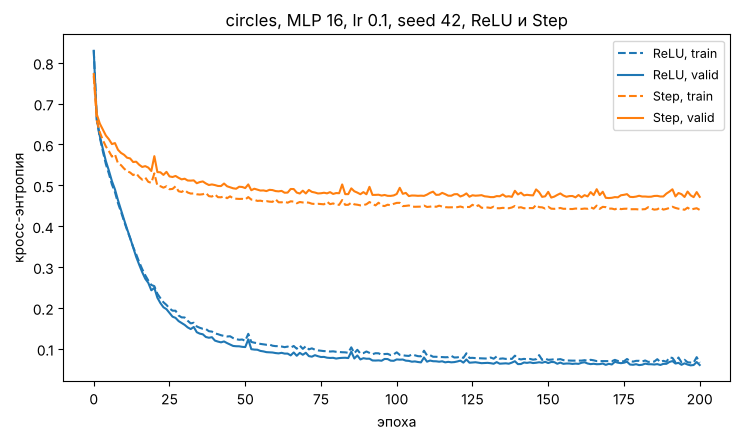

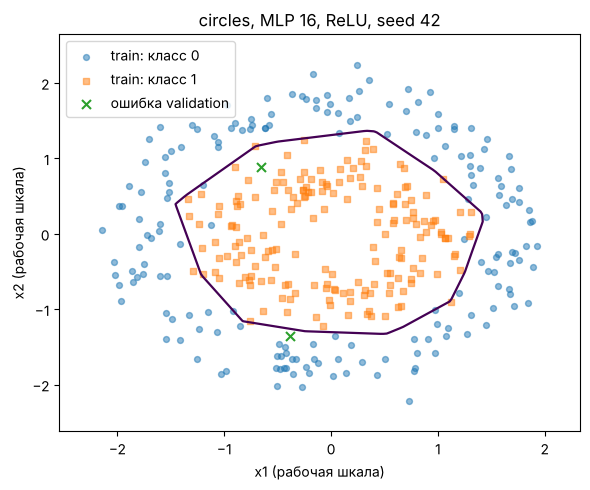

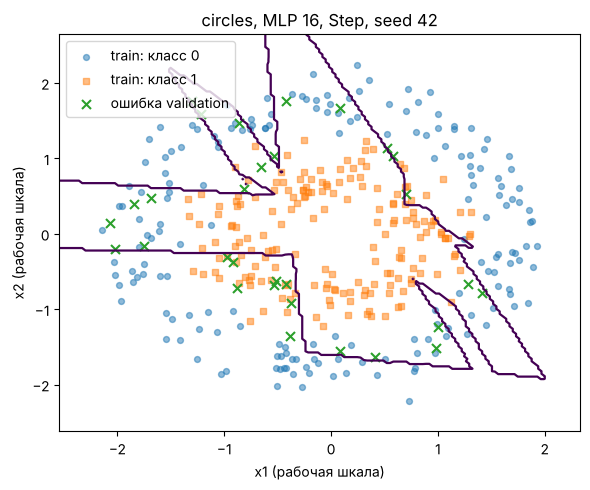

In [23]:
# Сравнение активаций по трём инициализациям.
seeds_24 = [42, 43, 44]
runs_24 = {
    (act, seed): run_config("circles", "mlp", hidden=best_width, activation=act, seed=seed, lr=best_lr)
    for seed in seeds_24
    for act in ("relu", "step")
}
# В каждой паре начальные параметры совпадают
for seed in seeds_24:
    assert all(np.array_equal(a, b) for a, b in
               zip(runs_24[("relu", seed)]["initial"], runs_24[("step", seed)]["initial"]))

rows_24 = []
for (act, seed), record in runs_24.items():
    W1_change = np.linalg.norm(record["model"].layers[0].W - record["initial"][0])
    rows_24.append({**summary_row(record), "норма изменения W1": W1_change,
                    "норма W1 в начале": np.linalg.norm(record["initial"][0])})
table_24 = pd.DataFrame(rows_24).sort_values(["активация", "seed"])
display(table_24[["модель", "seed", "lr", "эпох", "batch", "статус", "train loss", "valid loss",
                  "train acc", "valid acc", "норма изменения W1", "норма W1 в начале"]])

agg_24 = (
    table_24.groupby("активация")["valid acc"]
    .agg(["mean", lambda s: s.std(ddof=1)])
    .set_axis(["среднее valid acc", "std valid acc, ddof=1"], axis=1)
)
display(agg_24)

plot_loss_curves(
    [("ReLU", runs_24[("relu", SEED)]), ("Step", runs_24[("step", SEED)])],
    f"circles, MLP {best_width}, lr {best_lr}, seed {SEED}, ReLU и Step",
)
c = prepared["circles"]
for act, label in [("relu", "ReLU"), ("step", "Step")]:
    plot_boundary(runs_24[(act, SEED)]["model"], c["X_train"], c["y_train"],
                  c["X_valid"], c["y_valid"], f"circles, MLP {best_width}, {label}, seed {SEED}")


**Обсуждение результатов:**

Диагностика одного шага подтверждает механизм. У Step нормы градиентов по W1 и b1 равны нулю, ненулевые градиенты только у выходного слоя, 0.46 и 0.20. Норма изменения каждого параметра ровно в 10 раз меньше нормы его градиента, как и должно быть у SGD без инерции при lr 0.1. За один шаг loss у обеих сетей снизился почти одинаково, у ReLU с 0.775 до 0.755, у Step с 0.719 до 0.696. Снижение в обоих случаях близко к $\mathrm{lr} \cdot \|g\|^2$, и у Step градиент по выходному слою даже немного больше, потому что при тех же весах её скрытые выходы равны 0 или 1 и логиты на старте другие. Так что по одному шагу преимущество ReLU не видно, оно накапливается за обучение. У ReLU первый слой сдвинулся по норме на величину от 3.0 до 3.7, и это сравнимо с его начальной нормой, которая тоже от 3.0 до 3.7. Значит, признаки скрытого слоя по сути выучены заново. У Step сдвиг ровно 0.

По трём seed ReLU получает на validation 0.983 со стандартным отклонением 0, а Step получает 0.761 со стандартным отклонением 0.019. У Step и на train accuracy низкая, от 0.74 до 0.82, значит это недообучение из-за фиксированных признаков, а не переобучение. На графике граница Step собрана из кусков случайных прямых первого слоя и не может пройти там, где такой прямой нет. По сути это персептрон Розенблатта со случайным неизменяемым первым слоем. К инициализации Step намного чувствительнее. Её valid loss меняется от 0.41 до 0.49, а у ReLU от 0.061 до 0.069. Одинаковая accuracy ReLU при трёх seed это совпадение на уровне двух ошибок из 120, а не доказательство полной устойчивости.

У сравнения есть ограничения. Шаг 0.1 выбран для ReLU, и для Step он может быть не лучшим. Но у Step обучается только выходной слой, то есть решается выпуклая задача логистической регрессии над фиксированными признаками, и её кривая loss к эпохе 200 почти выходит на плато, так что качество упирается в признаки, а не в шаг. Три seed слишком мало, чтобы надёжно оценить разброс, стандартное отклонение по трём точкам само сильно шумит. И сравнение сделано только при ширине 16. При гораздо большей ширине случайных прямых было бы больше, и Step приблизила бы окружность лучше, так что вывод относится именно к этой ширине.


### 2.5. Итоговая оценка

По результатам пунктов 2.2–2.4 выберите одну из конфигураций сети со скрытым
слоем для `circles`. До обращения к test зафиксируйте архитектуру,
предобработку и режим обучения, обоснуйте выбор. Используйте сохранённую
модель с `seed=SEED`. Линейный классификатор из пункта 2.2 служит базовой моделью.

Оцените обе модели на test набора `circles`. Представьте таблицу из двух строк
с настройками, validation loss/accuracy выбранных запусков и test loss/accuracy.
После просмотра test конфигурации не меняйте; дообучение на train + validation
не предусмотрено. Тестовая часть `clouds` в работе не используется.

Разберите 3–5 ошибок выбранной сети: приведите координаты объектов, истинные
и предсказанные классы либо отметьте ошибки на диаграмме. Если ошибок меньше,
покажите все; если их нет, укажите это явно.

Сопоставьте итоговую оценку с выводами предыдущих экспериментов. Укажите
ограничение проведённого исследования и предложите следующий эксперимент,
не выполняя его.


**Выбранная конфигурация и обоснование:**

Я выбираю сеть с одним скрытым слоем из 16 нейронов ReLU, стандартизацию по train, lr 0.1, 200 эпох, батч 32 и уже обученную модель с seed 42. Ширину 16 я выбрал в серии A по valid loss, ширина 64 не лучше в пределах шума и содержит в 4 раза больше параметров. Шаг 0.1 выбран в серии B, потому что при 0.01 сеть недообучается, а при 0.5 обучение сильно шумит. ReLU выбрана вместо Step по результатам пункта 2.4, где в среднем по трём seed она дала 0.983 против 0.761. Стандартизация обоснована в пункте 2.1 и подтверждена опытом после пункта 2.2. Базовой моделью служит линейный классификатор из 2.2. Всё это зафиксировано до обращения к test.


,настройки,valid loss,valid acc,test loss,test acc
модель,,,,,
базовая модель,"Linear(2, 2), seed 42, lr 0.1, 200 эпох, батч 32, стандартизация по train",0.6934,0.5167,0.6937,0.5250
выбранная сеть,"MLP 16, ReLU, seed 42, lr 0.1, 200 эпох, батч 32, стандартизация по train",0.0605,0.9833,0.0481,0.9917


Ошибок выбранной сети на test 1 из 120


,x1 в исходной шкале,x2 в исходной шкале,радиус в исходной шкале,истинный класс,предсказанный класс,вероятность предсказанного класса
индекс в test,,,,,,
78,-0.4802,0.5272,0.7131,0,1,0.7741


,объектов,ошибок правила по радиусу,ошибок выбранной сети,accuracy правила,accuracy сети
часть,,,,,
train,360,14,7,0.9611,0.9806
valid,120,1,2,0.9917,0.9833
test,120,3,1,0.9750,0.9917


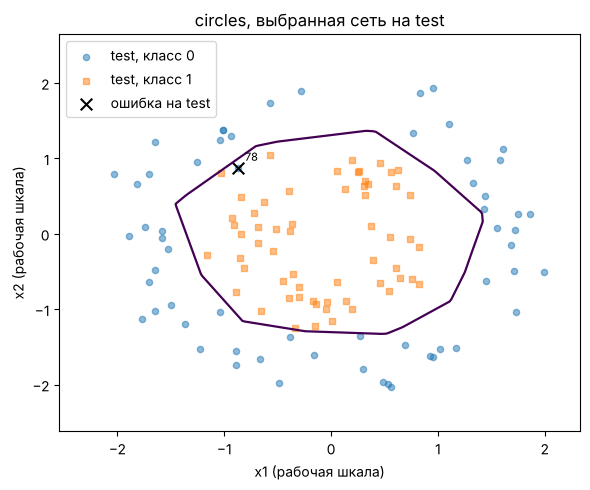

In [24]:
# Итоговая оценка.
# Конфигурация зафиксирована по validation до этой ячейки, test используется только здесь
final_records = {
    "базовая модель": results_22[("circles", "linear")],
    "выбранная сеть": runs_24[("relu", SEED)],
}
c = prepared["circles"]
final_rows = []
for role, record in final_records.items():
    test_metrics = evaluate(record["model"], c["X_test"], c["y_test"])
    last = record["history"].iloc[-1]
    cfg = record["config"]
    final_rows.append(
        {
            "модель": role,
            "настройки": f"{cfg['модель']}, seed {cfg['seed']}, lr {cfg['lr']}, "
                         f"{cfg['эпох']} эпох, батч {cfg['batch']}, стандартизация по train",
            "valid loss": last["valid_loss"],
            "valid acc": last["valid_acc"],
            "test loss": test_metrics["loss"],
            "test acc": test_metrics["acc"],
        }
    )
final_table = pd.DataFrame(final_rows).set_index("модель")
with pd.option_context("display.max_colwidth", None):
    display(final_table)

# Ошибки выбранной сети на test
chosen = final_records["выбранная сеть"]["model"]
test_logits = chosen.forward(c["X_test"])
test_pred = test_logits.argmax(axis=1)
wrong_idx = np.flatnonzero(test_pred != c["y_test"])
X_test_raw = data["circles"]["X_test"]
test_probs = np.exp(test_logits - test_logits.max(axis=1, keepdims=True))
test_probs /= test_probs.sum(axis=1, keepdims=True)
errors_table = pd.DataFrame(
    {
        "x1 в исходной шкале": X_test_raw[wrong_idx, 0],
        "x2 в исходной шкале": X_test_raw[wrong_idx, 1],
        "радиус в исходной шкале": np.linalg.norm(X_test_raw[wrong_idx], axis=1),
        "истинный класс": c["y_test"][wrong_idx],
        "предсказанный класс": test_pred[wrong_idx],
        "вероятность предсказанного класса": test_probs[wrong_idx, test_pred[wrong_idx]],
    },
    index=pd.Index(wrong_idx, name="индекс в test"),
)
print(f"Ошибок выбранной сети на test {len(wrong_idx)} из {len(c['y_test'])}")
display(errors_table.sort_values("вероятность предсказанного класса", ascending=False))

# Для сравнения правило по радиусу. make_circles кладёт класс 0 на окружность радиуса 1,
# класс 1 на окружность радиуса 0.5 и добавляет гауссов шум 0.12. Граница посередине,
# на радиусе 0.75, близка к оптимальной, поэтому ошибки этого правила показывают уровень
# неустранимого шума. Для выбора модели правило не используется.
oracle_rows = []
for part in ("train", "valid", "test"):
    radius = np.linalg.norm(data["circles"][f"X_{part}"], axis=1)
    rule = (radius < 0.75).astype(np.int64)
    net_pred = chosen.forward(c[f"X_{part}"]).argmax(axis=1)
    y_part = c[f"y_{part}"]
    oracle_rows.append({
        "часть": part,
        "объектов": len(y_part),
        "ошибок правила по радиусу": int(np.sum(rule != y_part)),
        "ошибок выбранной сети": int(np.sum(net_pred != y_part)),
        "accuracy правила": float(np.mean(rule == y_part)),
        "accuracy сети": float(np.mean(net_pred == y_part)),
    })
display(pd.DataFrame(oracle_rows).set_index("часть"))

# Граница выбранной сети и объекты test, ошибки отмечены крестиком
low, high = c["X_train"].min(axis=0) - 0.4, c["X_train"].max(axis=0) + 0.4
xx, yy = np.meshgrid(np.linspace(low[0], high[0], 200), np.linspace(low[1], high[1], 200))
grid_logits = chosen.forward(np.column_stack([xx.ravel(), yy.ravel()]))
score = (grid_logits[:, 1] - grid_logits[:, 0]).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(6, 5))
ax.contour(xx, yy, score, levels=[0.0], linewidths=1.6)
for label, marker in [(0, "o"), (1, "s")]:
    mask = c["y_test"] == label
    ax.scatter(*c["X_test"][mask].T, marker=marker, s=20, alpha=0.5, label=f"test, класс {label}")
if len(wrong_idx):
    ax.scatter(*c["X_test"][wrong_idx].T, marker="x", s=70, color="black", label="ошибка на test")
    for i in wrong_idx:
        ax.annotate(str(i), c["X_test"][i], textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.set(title="circles, выбранная сеть на test", xlabel="x1 (рабочая шкала)",
       ylabel="x2 (рабочая шкала)", xlim=(low[0], high[0]), ylim=(low[1], high[1]))
ax.legend()
fig.tight_layout()
plt.show()


**Обсуждение результатов:**

На test выбранная сеть получила accuracy 0.992 и loss 0.048, а линейная модель 0.525 и 0.694, то есть уровень константы, как и на validation. У сети результат на test немного лучше, чем на validation, где было 0.983 и 0.061, но это одна ошибка против двух на 120 объектах, и такая разница случайна.

Ошибка на test всего одна, поэтому разбираю её. Это точка с координатами $(-0.48, 0.53)$ из внешнего кольца, класс 0, с радиусом 0.713. Сеть отнесла её к внутреннему кольцу с вероятностью 0.77. Радиус этой точки меньше середины между кольцами 0.75, то есть шум перенёс её на сторону чужого класса, и правило по радиусу, взятое из устройства генератора, тоже ошиблось бы на ней. Это правило близко к оптимальному, и оно ошибается на 1 объекте validation и на 3 объектах test, а сеть на 2 и на 1. На train сеть ошибается на 7 объектах, а правило на 14. Значит, сеть немного подстроилась под шум train, но на отложенных данных это не навредило.

Итог согласуется с выводами пунктов 2.2, 2.3 и 2.4. Скрытый слой нужен из-за геометрии circles, ширины 16 хватает, шаг 0.1 даёт устойчивое обучение, и сеть почти дошла до уровня неустранимого шума. Оставшиеся ошибки дают объекты, которые шум перенёс через границу.

Главное ограничение исследования в том, что выводы сделаны на одном разбиении и почти все запуски выполнены с одним seed, а в validation и test всего по 120 объектов, поэтому разница в один или два объекта не значима. Следующим экспериментом я бы повторил сравнение ширин 16 и 64 и шагов 0.1 и 0.5 на нескольких seed и в режиме скользящего контроля по train вместе с validation, с ранней остановкой по valid loss. Так можно оценить разброс и проверить, выигрывает ли lr 0.5, если остановиться в его минимуме.
